# Ganga fecal indicators → PHRQ → illness risk: step-by-step

**Paper:** *Linking fecal indicator limits to gastrointestinal illness risk for ritual bathing in the Ganga at Varanasi, India* (Tekile & Singh).
**What this notebook does:** it computes, step by step, the calculations behind the manuscript and Supplementary Information from the 44-sample dataset, and draws the figures that can be generated from data (the exceptions are listed in the last cell). Each step has (i) a short explanation, (ii) the code, (iii) the outcome as a table and/or figure, and (iv) where relevant a check against the value reported in the paper.

> **How to run in Google Colab:** *File → Upload notebook*, then *Runtime → Run all* (about 2–5 minutes on the free tier; about 1½ minutes on a laptop). Nothing needs to be uploaded: the dataset is embedded. The notebook also runs unchanged in Jupyter or VS Code (see the README for package versions). All figures and tables are also saved to an `outputs/` folder and zipped in the last cell.

> **Important:** Because the model is a Monte Carlo simulation, results agree with the paper to within simulation error (about 1–3 %), not digit for digit.

| Step | Content | Paper section | Figures / tables produced |
|---|---|---|---|
| 0 | Setup, parameters | 2 | – |
| 1 | Data (44 samples) | 2.1–2.2 | Table S1 |
| 2 | Indicator concentrations and CPCB exceedance | 3.1 | **Fig. 2**, Table 1 |
| 3 | Relationships between indicators; FC/FS ratio | 3.2–3.3 | extra figures E6, E7 |
| 4 | PHRQ and tiers; international grades | 3.4–3.5 | **Fig. 3**, extra figure E5, Table S3 |
| 5 | The QMRA model (inputs, dose–response, ingestion) | 2.6 | Table S2, extra figures E1–E2 |
| 6 | Distribution fits for site-level risk | 2.6 | extra table (distribution fits), extra figure E3 |
| 7 | Calibration of the scaling factor κ; benchmark consistency | 2.7, 3.6 | **Fig. 4**, extra table (benchmark consistency) |
| 8 | Per-event illness at the monitored sites | 3.7 | **Fig. 5**, Table S4, extra table (sample-level illness) |
| 9 | PHRQ-to-risk map | 3.8 | **Fig. 6**, Table S5 (A) |
| 10 | Sensitivity analysis and the ingestion-volume check | 3.9 | Table S5 (B), extra table (rank correlations), extra figure E4 |
| 11 | Dose–response alternatives (subset) | 3.9 | Table 2 (primary set + 4 of the 12 alternatives) |
| 12 | Statistics quoted in the text; annual risk | 2.3, 3.1–3.4, 3.7 | extra tables: exceedance with Wilson intervals, monthly compliance, mixed models and tests, annual illness probability |
| 13 | Figures that are not computed from the data | – | workflow diagram (Fig. 1 and Fig. S1 are not redistributed) |
| 14 | Reproducibility scoreboard and export | – | `outputs/` and a zip file |


## 0 · Setup

Libraries (numpy, scipy, pandas, matplotlib, mpmath – all preinstalled in Colab), random seed, Monte Carlo sizes, colors, and a few helper functions.
Change the settings in the first block if you want faster (fewer draws) or smoother (more draws) results.

In [1]:
import sys, subprocess, importlib, io, base64, warnings, zipfile, time, math
from pathlib import Path
for _pkg in ("numpy", "scipy", "pandas", "matplotlib", "mpmath", "statsmodels"):
    try:
        importlib.import_module(_pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mpmath as mp
from decimal import Decimal, ROUND_HALF_UP
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch, FancyBboxPatch
from scipy import stats
from scipy.optimize import brentq
from IPython.display import display, Markdown, Image as IPImage
warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- settings you can change
SEED     = 20261026     # fixed seed
N_MAP    = 50_000       # Monte Carlo draws per PHRQ value        (paper: 50,000)
N_SITE   = 100_000      # draws for site / season risk            (paper: 100,000)
N_SAMPLE = 20_000       # draws per observed sample               (paper: 20,000)
N_CAL    = 1_000_000    # draws for the kappa calibration         (paper: 400,000)
B_BOOT   = 10_000       # bootstrap resamples for GM and P95      (paper: 10,000)
B_REG    = 3_000        # bootstrap refits of the regressions     (paper: 3,000)
N_ANNUAL = 10_000       # iterations for the annual-risk simulation (paper: 10,000)

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# ---------------------------------------------------------------- look
COL = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73", pink="#CC79A7",
           orange="#E69F00", sky="#56B4E9", ink="#222222")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.linewidth": 0.8, "legend.frameon": False})
SITE = {"A": "U/S Assi Ghat", "B": "Assi Ghat", "C": "Dashashwamedh Ghat", "D": "Kardameshwar Pond"}
SITE_STYLE = {"A": (COL["blue"], "o", "-", True), "B": (COL["vermillion"], "s", "--", False),
              "C": (COL["green"], "^", "-.", True), "D": (COL["pink"], "D", ":", False)}   # colour, marker, line, filled
SEASONS = ["Monsoon", "Post-monsoon", "Dry"]
SEASON_STYLE = {"Monsoon": (COL["blue"], "o"), "Post-monsoon": (COL["orange"], "s"),
                "Dry": (COL["vermillion"], "^")}

# ---------------------------------------------------------------- helpers
def save_fig(fig, name):
    """save a figure to outputs/ and display it"""
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def save_table(table, name, index=True):
    table.to_csv(OUT / f"{name}.csv", index=index)
    return table

def sig(x, n=2):
    """n significant figures (round half up), no exponent, thousands separators"""
    if x is None or (isinstance(x, float) and np.isnan(x)): return "–"
    if x == 0: return "0"
    dx = Decimal(repr(float(x))); e = dx.adjusted()
    v = dx.quantize(Decimal(1).scaleb(e - n + 1), rounding=ROUND_HALF_UP)
    return f"{int(v):,}" if e - n + 1 >= 0 else f"{v:f}"

def plain_ticks(ax, which, ticks):
    """label log-axis ticks with plain numbers (0.01, 0.1, 1, 10 ...) instead of powers of ten"""
    getattr(ax, f"set_{which}ticks")(ticks)
    getattr(ax, f"set_{which}ticklabels")([f"{t:g}" for t in ticks])

def check(label, model, reported, tol=0.05):
    """print a one-line comparison with the value reported in the paper"""
    ok = abs(model - reported) <= tol * abs(reported)
    print(f"  {'✓' if ok else '⚠'} {label}: notebook {model:.4g}  |  paper {reported:.4g}")
    return ok

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", __import__("scipy").__version__,
      "| pandas", pd.__version__, "| matplotlib", mpl.__version__, "| mpmath", mp.__version__)

Python 3.12.3 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | matplotlib 3.11.2 | mpmath 1.3.0


## 1 · Data

**Table S1** – 44 samples: 4 sites × 11 monthly rounds (17 June 2025 – 15 May 2026; no sample in March 2026). Concentrations are most-probable-number (MPN) per 100 mL for total coliforms (TC), fecal coliforms (FC), *E. coli*, fecal streptococci (FS) and enterococci, measured by the multiple-tube fermentation method (Fig. S1, shown in Step 12).
Sites: **A** upstream of Assi Ghat (Assi River confluence), **B** Assi Ghat, **C** Dashashwamedh Ghat, **D** Kardameshwar Pond. Seasons: monsoon (Jun–Sep), post-monsoon (Oct–Nov), dry (Dec–May).

The CPCB maximum permissible limits for bathing water are FC = 2,500 and FS = 500 MPN per 100 mL; the **Public Health Risk Quotient** is PHRQ = concentration ÷ limit.

In [2]:
#@title Embedded dataset (Table S1)  { display-mode: "form" }
CSV = """date,site_code,site,season,total_coliform,fecal_coliform,e_coli,fecal_streptococci,enterococci
2025-06-17,A,U/S Assi Ghat,Monsoon,70000,26000,6100,20000,4000
2025-06-17,B,Assi Ghat,Monsoon,540000,40000,12000,220000,11000
2025-06-17,C,Dashashwamedh Ghat,Monsoon,48000,34000,9300,27000,8300
2025-06-17,D,Kardameshwar Pond,Monsoon,38000,26000,6800,21000,1800
2025-07-15,A,U/S Assi Ghat,Monsoon,48000,25000,8200,6100,3700
2025-07-15,B,Assi Ghat,Monsoon,430000,39000,10000,170000,12000
2025-07-15,C,Dashashwamedh Ghat,Monsoon,49000,22000,4000,22000,6800
2025-07-15,D,Kardameshwar Pond,Monsoon,33000,21000,6100,3700,1800
2025-08-19,A,U/S Assi Ghat,Monsoon,47000,26000,1800,11000,2000
2025-08-19,B,Assi Ghat,Monsoon,38000,21000,8100,8200,6100
2025-08-19,C,Dashashwamedh Ghat,Monsoon,150000,33000,5500,27000,6800
2025-08-19,D,Kardameshwar Pond,Monsoon,24000,8200,2000,1800,1800
2025-09-23,A,U/S Assi Ghat,Monsoon,39000,17000,7800,14000,9300
2025-09-23,B,Assi Ghat,Monsoon,49000,26000,6800,20000,9200
2025-09-23,C,Dashashwamedh Ghat,Monsoon,41000,21000,4000,39000,22000
2025-09-23,D,Kardameshwar Pond,Monsoon,32000,14000,6800,21000,11000
2025-10-20,A,U/S Assi Ghat,Post-monsoon,21000,14000,4000,11000,1800
2025-10-20,B,Assi Ghat,Post-monsoon,39000,17000,9200,13000,2000
2025-10-20,C,Dashashwamedh Ghat,Post-monsoon,39000,14000,6100,9200,4000
2025-10-20,D,Kardameshwar Pond,Post-monsoon,20000,12000,3700,6800,1800
2025-11-26,A,U/S Assi Ghat,Post-monsoon,22000,22000,1800,6000,2000
2025-11-26,B,Assi Ghat,Post-monsoon,31000,7800,1800,6100,1800
2025-11-26,C,Dashashwamedh Ghat,Post-monsoon,8100,2000,1800,2000,2000
2025-11-26,D,Kardameshwar Pond,Post-monsoon,4500,2000,1800,6000,2000
2025-12-25,A,U/S Assi Ghat,Dry,170000,26000,6100,12000,4000
2025-12-25,B,Assi Ghat,Dry,210000,40000,12000,11000,4500
2025-12-25,C,Dashashwamedh Ghat,Dry,140000,34000,9300,26000,8300
2025-12-25,D,Kardameshwar Pond,Dry,110000,26000,6800,6800,1800
2026-01-20,A,U/S Assi Ghat,Dry,25000,25000,8200,14000,3700
2026-01-20,B,Assi Ghat,Dry,47000,39000,10000,39000,12000
2026-01-20,C,Dashashwamedh Ghat,Dry,26000,22000,4000,14000,1800
2026-01-20,D,Kardameshwar Pond,Dry,31000,21000,6100,24000,3700
2026-02-13,A,U/S Assi Ghat,Dry,2100,1500,180,2600,450
2026-02-13,B,Assi Ghat,Dry,2100,1400,180,3300,450
2026-02-13,C,Dashashwamedh Ghat,Dry,2600,2600,360,1400,370
2026-02-13,D,Kardameshwar Pond,Dry,2000,930,450,4800,360
2026-04-15,A,U/S Assi Ghat,Dry,13000,1700,400,1300,450
2026-04-15,B,Assi Ghat,Dry,13000,2200,1100,400,200
2026-04-15,C,Dashashwamedh Ghat,Dry,1400,930,200,1300,780
2026-04-15,D,Kardameshwar Pond,Dry,17333,2933,687,500,200
2026-05-15,A,U/S Assi Ghat,Dry,70000,49000,23000,3300,1700
2026-05-15,B,Assi Ghat,Dry,220000,140000,43000,28000,4900
2026-05-15,C,Dashashwamedh Ghat,Dry,11000,4900,3300,11000,3300
2026-05-15,D,Kardameshwar Pond,Dry,3300,2700,2300,2200,2200"""

FC_LIMIT, FS_LIMIT = 2500.0, 500.0          # CPCB maximum permissible limits (MPN/100 mL)

df = pd.read_csv(io.StringIO(CSV), parse_dates=["date"])
df["site_name"] = df.site_code.map(SITE)
df["phrq_fc"] = df.fecal_coliform / FC_LIMIT
df["phrq_fs"] = df.fecal_streptococci / FS_LIMIT
df["fc_fs_ratio"] = df.fecal_coliform / df.fecal_streptococci
# To use your own file instead:  df = pd.read_csv("my_file.csv", parse_dates=["date"])  (same column names)
print(df.shape)

(44, 13)


In [3]:
# ---- optional check: is the embedded dataset identical to the CSV file that ships with this repository? ----
_csv = next((p for p in (Path("data/ganga_dataset.csv"), Path("../data/ganga_dataset.csv"), Path("ganga_dataset.csv")) if p.exists()), None)
if _csv is None:
    print("No separate CSV found next to the notebook - not needed, the dataset is embedded above.")
else:
    _ext = pd.read_csv(_csv, parse_dates=["date"])
    _cols = ["date", "site_code", "site", "season", "total_coliform", "fecal_coliform", "e_coli", "fecal_streptococci", "enterococci"]
    try:
        pd.testing.assert_frame_equal(_ext[_cols].reset_index(drop=True), df[_cols].reset_index(drop=True), check_dtype=False)
        print(f"{_csv}: identical to the embedded dataset ({len(_ext)} rows).")
    except AssertionError as err:
        print(f"WARNING: {_csv} differs from the embedded dataset:\n{err}")

../data/ganga_dataset.csv: identical to the embedded dataset (44 rows).


In [4]:
# data checks
print(f"{len(df)} samples, {df.date.min().date()} to {df.date.max().date()}; missing values: {int(df.isna().sum().sum())}")
months = sorted(df.date.dt.to_period("M").unique())
print("months sampled:", ", ".join(str(m) for m in months), "| March 2026 sampled:", pd.Period("2026-03") in months)
display(pd.crosstab(df.site_name, df.season).reindex(columns=SEASONS))

table_s1 = df[["date", "site_code", "site_name", "season", "total_coliform", "fecal_coliform", "e_coli",
               "fecal_streptococci", "enterococci"]].copy()
table_s1["date"] = table_s1.date.dt.strftime("%Y-%m-%d")
table_s1.columns = ["Date", "Site", "Site name", "Season", "TC", "FC", "E. coli", "FS", "Enterococci"]
display(table_s1.style.hide(axis="index").format({c: "{:,.0f}" for c in ["TC", "FC", "E. coli", "FS", "Enterococci"]}))
save_table(table_s1, "Table_S1_dataset", index=False);

44 samples, 2025-06-17 to 2026-05-15; missing values: 0
months sampled: 2025-06, 2025-07, 2025-08, 2025-09, 2025-10, 2025-11, 2025-12, 2026-01, 2026-02, 2026-04, 2026-05 | March 2026 sampled: False


season,Monsoon,Post-monsoon,Dry
site_name,,,
Assi Ghat,4,2,5
Dashashwamedh Ghat,4,2,5
Kardameshwar Pond,4,2,5
U/S Assi Ghat,4,2,5


Date,Site,Site name,Season,TC,FC,E. coli,FS,Enterococci
2025-06-17,A,U/S Assi Ghat,Monsoon,"70,000","26,000","6,100","20,000","4,000"
2025-06-17,B,Assi Ghat,Monsoon,"540,000","40,000","12,000","220,000","11,000"
2025-06-17,C,Dashashwamedh Ghat,Monsoon,"48,000","34,000","9,300","27,000","8,300"
2025-06-17,D,Kardameshwar Pond,Monsoon,"38,000","26,000","6,800","21,000","1,800"
2025-07-15,A,U/S Assi Ghat,Monsoon,"48,000","25,000","8,200","6,100","3,700"
2025-07-15,B,Assi Ghat,Monsoon,"430,000","39,000","10,000","170,000","12,000"
2025-07-15,C,Dashashwamedh Ghat,Monsoon,"49,000","22,000","4,000","22,000","6,800"
2025-07-15,D,Kardameshwar Pond,Monsoon,"33,000","21,000","6,100","3,700","1,800"
2025-08-19,A,U/S Assi Ghat,Monsoon,"47,000","26,000","1,800","11,000","2,000"
2025-08-19,B,Assi Ghat,Monsoon,"38,000","21,000","8,100","8,200","6,100"


## 2 · Indicator concentrations and exceedance of the CPCB limits

**Fig. 2** plots the four indicators (FC, FS, *E. coli*, enterococci) at each site through the year against the two CPCB limits (dashed lines: FC 2,500 in blue, FS 500 in orange). **Table 1** summarises each indicator by site and season as the geometric mean (GM) with the minimum–maximum, and counts the samples above the limits.
GM = exp(mean(ln *x*)), because microbial concentrations are roughly log-normal.

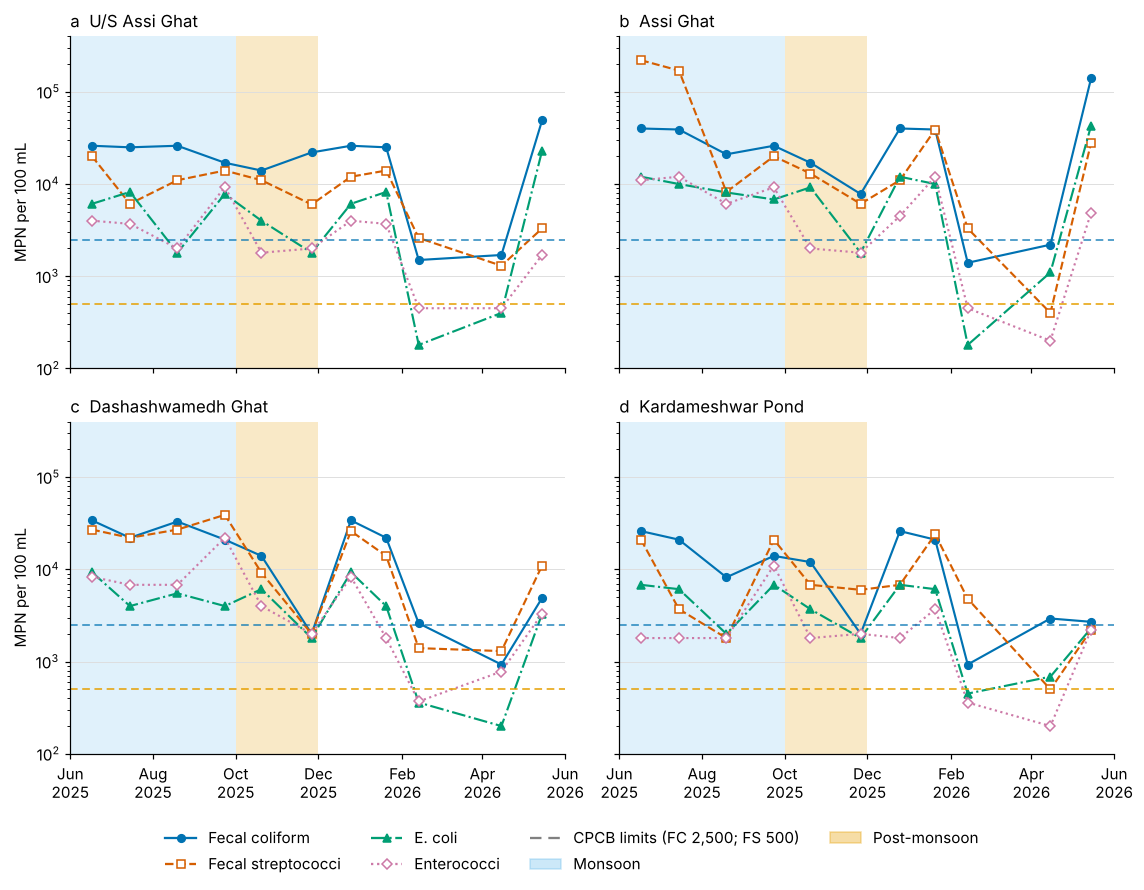

In [5]:
# ---- Fig. 2: indicator concentrations at the four sites -------------------------------
series = [("fecal_coliform", "Fecal coliform", COL["blue"], "o", "-"),
          ("fecal_streptococci", "Fecal streptococci", COL["vermillion"], "s", "--"),
          ("e_coli", "E. coli", COL["green"], "^", "-."),
          ("enterococci", "Enterococci", COL["pink"], "D", ":")]
x0, x1 = pd.Timestamp("2025-06-01"), pd.Timestamp("2026-06-01")
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.8), sharex=True, sharey=True)
for i, (ax, (code_, name)) in enumerate(zip(axes.ravel(), SITE.items())):
    g = df[df.site_code == code_].sort_values("date")
    ax.axvspan(x0, pd.Timestamp("2025-10-01"), color=COL["sky"], alpha=0.18, lw=0)
    ax.axvspan(pd.Timestamp("2025-10-01"), pd.Timestamp("2025-12-01"), color=COL["orange"], alpha=0.22, lw=0)
    for col_, lab, c, m, ls in series:
        ax.plot(g.date, g[col_], color=c, marker=m, ls=ls, ms=5, lw=1.4, mfc="white" if m in "sD" else c)
    ax.axhline(FC_LIMIT, color=COL["blue"], ls=(0, (5, 3)), lw=1.0, alpha=0.85)
    ax.axhline(FS_LIMIT, color=COL["orange"], ls=(0, (5, 3)), lw=1.0)
    ax.set_yscale("log"); ax.set_ylim(100, 4e5); ax.set_xlim(x0, x1)
    ax.set_title(f"{'abcd'[i]}  {name}", loc="left", fontsize=11)
    ax.grid(axis="y", color="#dddddd", lw=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[6, 8, 10, 12, 2, 4]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: mdates.num2date(v).strftime("%b\n%Y")))
for ax in axes[:, 0]: ax.set_ylabel("MPN per 100 mL")
handles = [Line2D([], [], color=c, marker=m, ls=ls, ms=5, mfc="white" if m in "sD" else c, label=lab)
           for _, lab, c, m, ls in series]
handles += [Line2D([], [], color="gray", ls=(0, (5, 3)), label="CPCB limits (FC 2,500; FS 500)"),
            Patch(color=COL["sky"], alpha=0.3, label="Monsoon"), Patch(color=COL["orange"], alpha=0.35, label="Post-monsoon")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, "Fig2_indicator_concentrations")

In [6]:
# ---- Table 1: geometric mean (min–max) and exceedance of the CPCB limits ---------------
def gmean(x): return float(np.exp(np.log(np.asarray(x, float)).mean()))

cols = [("fecal_coliform", "Fecal coliform"), ("fecal_streptococci", "Fecal streptococci"),
        ("e_coli", "E. coli"), ("enterococci", "Enterococci")]
groups = ([("All samples", df)] + [(SITE[s], df[df.site_code == s]) for s in SITE]
          + [(s, df[df.season == s]) for s in SEASONS])
rows = []
for name, g in groups:
    r = {"Group": name, "n": len(g)}
    for c, lab in cols:
        r[lab] = f"{sig(gmean(g[c]), 2)} ({g[c].min():,.0f}–{g[c].max():,.0f})"
    nfc, nfs = int((g.fecal_coliform > FC_LIMIT).sum()), int((g.fecal_streptococci > FS_LIMIT).sum())
    r["FC > 2,500"] = f"{nfc}/{len(g)} ({100*nfc/len(g):.0f}%)"
    r["FS > 500"] = f"{nfs}/{len(g)} ({100*nfs/len(g):.0f}%)"
    rows.append(r)
table1 = pd.DataFrame(rows).set_index("Group")
display(table1)
save_table(table1, "Table1_indicator_summary")

print("Checks against Table 1 of the paper (all samples):")
check("GM fecal coliform", gmean(df.fecal_coliform), 12000, 0.03)
check("GM fecal streptococci", gmean(df.fecal_streptococci), 8600, 0.03)
check("GM E. coli", gmean(df.e_coli), 3400, 0.03)
check("GM enterococci", gmean(df.enterococci), 2500, 0.03)
print("  FC > 2,500:", int((df.fecal_coliform > FC_LIMIT).sum()), "of 44 (paper: 36);  FS > 500:",
      int((df.fecal_streptococci > FS_LIMIT).sum()), "of 44 (paper: 42)")

,n,Fecal coliform,Fecal streptococci,E. coli,Enterococci,"FC > 2,500",FS > 500
Group,,,,,,,
All samples,44,"12,000 (930–140,000)","8,600 (400–220,000)","3,400 (180–43,000)","2,500 (200–22,000)",36/44 (82%),42/44 (95%)
U/S Assi Ghat,11,"15,000 (1,500–49,000)","7,100 (1,300–20,000)","3,200 (180–23,000)","2,200 (450–9,300)",9/11 (82%),11/11 (100%)
Assi Ghat,11,"18,000 (1,400–140,000)","15,000 (400–220,000)","5,400 (180–43,000)","3,400 (200–12,000)",9/11 (82%),10/11 (91%)
Dashashwamedh Ghat,11,"10,000 (930–34,000)","9,800 (1,300–39,000)","2,800 (200–9,300)","3,500 (370–22,000)",9/11 (82%),11/11 (100%)
Kardameshwar Pond,11,"7,700 (930–26,000)","5,400 (500–24,000)","2,900 (450–6,800)","1,600 (200–11,000)",9/11 (82%),10/11 (91%)
Monsoon,16,"23,000 (8,200–40,000)","19,000 (1,800–220,000)","5,900 (1,800–12,000)","5,700 (1,800–22,000)",16/16 (100%),16/16 (100%)
Post-monsoon,8,"8,500 (2,000–22,000)","6,700 (2,000–13,000)","3,100 (1,800–9,200)","2,100 (1,800–4,000)",6/8 (75%),8/8 (100%)
Dry,20,"8,200 (930–140,000)","5,200 (400–39,000)","2,300 (180–43,000)","1,500 (200–12,000)",14/20 (70%),18/20 (90%)


Checks against Table 1 of the paper (all samples):
  ✓ GM fecal coliform: notebook 1.209e+04  |  paper 1.2e+04
  ✓ GM fecal streptococci: notebook 8633  |  paper 8600
  ✓ GM E. coli: notebook 3441  |  paper 3400
  ✓ GM enterococci: notebook 2548  |  paper 2500
  FC > 2,500: 36 of 44 (paper: 36);  FS > 500: 42 of 44 (paper: 42)


## 3 · Relationships between indicators, and the FC/FS source ratio

### 3a · Regressions on the log scale
Legacy indicators (FC, FS) are related to the preferred ones (*E. coli*, enterococci) by ordinary least squares on log₁₀ concentrations:
log₁₀ *y* = *a* + *b* · log₁₀ *x* + ε, ε ~ N(0, *s*²). The two regressions on **FC** (*E. coli* ~ FC and enterococci ~ FC) are the bridge used later to convert a PHRQ into predicted *E. coli* and enterococci concentrations (Step 9). Fig also shows enterococci ~ FS.
The shaded band is the 95 % *prediction* interval: ŷ ± *t*₀.₉₇₅,ₙ₋₂ · *s* · √(1 + 1/*n* + (*x* − x̄)²/*S*ₓₓ).

In [7]:
def ols_log(x, y):
    lx, ly = np.log10(np.asarray(x, float)), np.log10(np.asarray(y, float))
    n = len(lx); r = stats.linregress(lx, ly)
    resid = ly - (r.intercept + r.slope * lx)
    return dict(a=r.intercept, b=r.slope, s=float(np.sqrt((resid ** 2).sum() / (n - 2))), r2=r.rvalue ** 2,
                n=n, xbar=lx.mean(), sxx=float(((lx - lx.mean()) ** 2).sum()), lx=lx, ly=ly)

REGR = {"E. coli ~ FC": ols_log(df.fecal_coliform, df.e_coli),
        "Enterococci ~ FC": ols_log(df.fecal_coliform, df.enterococci),
        "Enterococci ~ FS": ols_log(df.fecal_streptococci, df.enterococci)}
reg_tbl = pd.DataFrame({k: {"intercept a": v["a"], "slope b": v["b"], "residual SD s": v["s"], "R²": v["r2"], "n": v["n"]}
                        for k, v in REGR.items()}).T
display(reg_tbl.round(3)); save_table(reg_tbl.round(4), "Table_regressions")
print("Checks against the paper (Section 2.8):")
check("E. coli ~ FC slope", REGR["E. coli ~ FC"]["b"], 0.929, 0.01); check("E. coli ~ FC intercept", REGR["E. coli ~ FC"]["a"], -0.256, 0.01)
check("E. coli ~ FC residual SD", REGR["E. coli ~ FC"]["s"], 0.242, 0.01)
check("Enterococci ~ FC slope", REGR["Enterococci ~ FC"]["b"], 0.677, 0.01); check("Enterococci ~ FC residual SD", REGR["Enterococci ~ FC"]["s"], 0.342, 0.01)

,intercept a,slope b,residual SD s,R²,n
E. coli ~ FC,-0.256,0.929,0.242,0.816,44.0
Enterococci ~ FC,0.642,0.677,0.342,0.542,44.0
Enterococci ~ FS,0.505,0.737,0.269,0.715,44.0


Checks against the paper (Section 2.8):
  ✓ E. coli ~ FC slope: notebook 0.9291  |  paper 0.929
  ✓ E. coli ~ FC intercept: notebook -0.2564  |  paper -0.256
  ✓ E. coli ~ FC residual SD: notebook 0.2417  |  paper 0.242
  ✓ Enterococci ~ FC slope: notebook 0.6772  |  paper 0.677
  ✓ Enterococci ~ FC residual SD: notebook 0.3417  |  paper 0.342


True

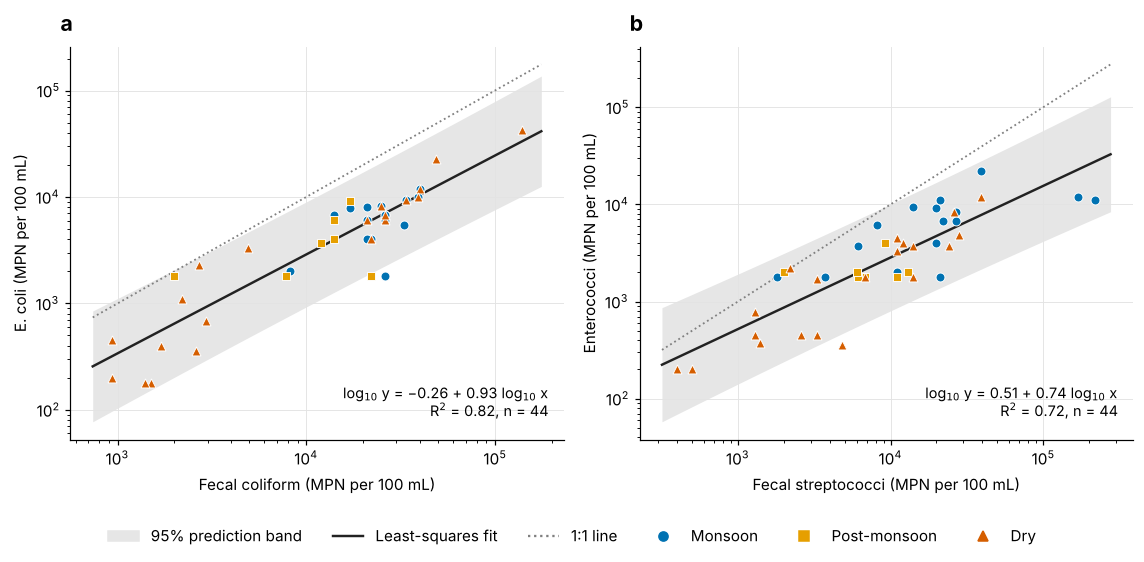

In [8]:
# ---- Extra figure E6: agreement between legacy and preferred indicators -------------------------
def pred_band(fit, xs):
    t = stats.t.ppf(0.975, fit["n"] - 2); lx = np.log10(xs)
    se = fit["s"] * np.sqrt(1 + 1 / fit["n"] + (lx - fit["xbar"]) ** 2 / fit["sxx"])
    mid = fit["a"] + fit["b"] * lx
    return 10 ** mid, 10 ** (mid - t * se), 10 ** (mid + t * se)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.9))
panels = [("fecal_coliform", "e_coli", "E. coli ~ FC", "Fecal coliform (MPN per 100 mL)", "E. coli (MPN per 100 mL)", "a"),
          ("fecal_streptococci", "enterococci", "Enterococci ~ FS", "Fecal streptococci (MPN per 100 mL)", "Enterococci (MPN per 100 mL)", "b")]
for ax, (xc, yc, key, xl, yl, tag) in zip(axes, panels):
    fit = REGR[key]
    xs = np.logspace(np.log10(df[xc].min()) - 0.1, np.log10(df[xc].max()) + 0.1, 100)
    mid, lo, hi = pred_band(fit, xs)
    ax.fill_between(xs, lo, hi, color="#e6e6e6", lw=0, zorder=1)
    ax.plot(xs, mid, color=COL["ink"], lw=1.6, zorder=3)
    ax.plot(xs, xs, color="gray", ls=":", lw=1.2, zorder=2)
    for s_ in SEASONS:
        g = df[df.season == s_]; c, m = SEASON_STYLE[s_]
        ax.scatter(g[xc], g[yc], c=c, marker=m, s=34, edgecolor="white", lw=0.6, zorder=4)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.grid(color="#e3e3e3", lw=0.6)
    sgn = "−" if fit["a"] < 0 else "+"
    ax.text(0.97, 0.05, f"log$_{{10}}$ y = {'−' if fit['a']<0 else ''}{abs(fit['a']):.2f} + {fit['b']:.2f} log$_{{10}}$ x\nR$^2$ = {fit['r2']:.2f}, n = {fit['n']}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5)
    ax.text(-0.02, 1.04, tag, transform=ax.transAxes, fontsize=14, fontweight="bold")
handles = [Patch(color="#e6e6e6", label="95% prediction band"), Line2D([], [], color=COL["ink"], lw=1.6, label="Least-squares fit"),
           Line2D([], [], color="gray", ls=":", label="1:1 line")]
handles += [Line2D([], [], color=SEASON_STYLE[s][0], marker=SEASON_STYLE[s][1], ls="", ms=6, label=s) for s in SEASONS]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, "FigE6_regressions")

### 3b · Source indication from the FC/FS ratio
The ratio of fecal coliforms to fecal streptococci in each sample indicates the predominant origin of fecal contamination (Geldreich & Kenner): **< 0.7 animal**, **0.7–4 mixed**, **> 4 human**.

ratio_class,Animal (<0.7),Mixed (0.7–4),Human (>4),Median FC/FS
site_name,,,,
U/S Assi Ghat,1,8,2,1.79
Assi Ghat,3,6,2,1.30
Dashashwamedh Ghat,2,9,0,1.22
Kardameshwar Pond,3,5,3,1.24
All sites,9,28,7,1.30


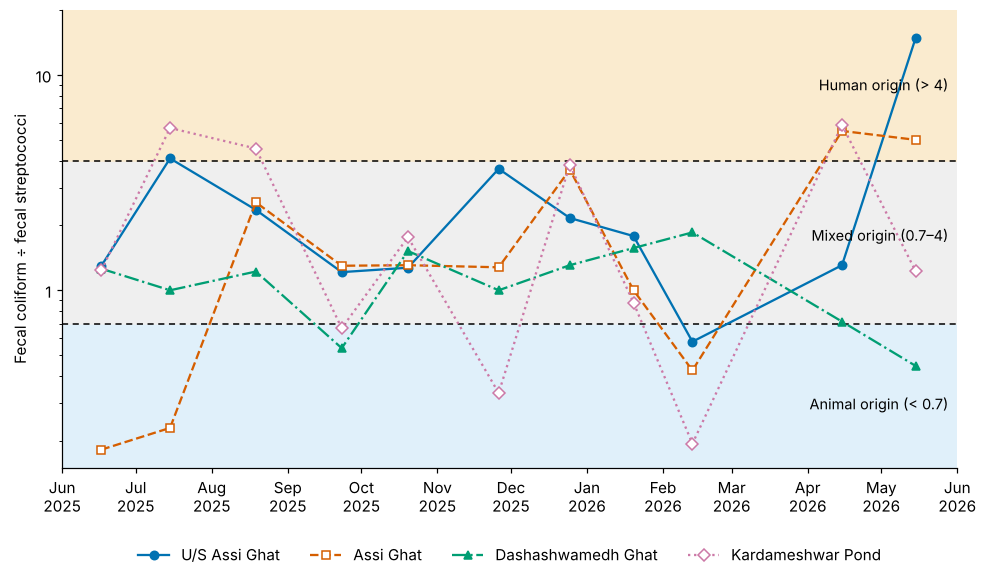

In [9]:
df["ratio_class"] = np.select([df.fc_fs_ratio < 0.7, df.fc_fs_ratio > 4], ["Animal (<0.7)", "Human (>4)"], "Mixed (0.7–4)")
ratio_tbl = (pd.crosstab(df.site_name, df.ratio_class).reindex(index=list(SITE.values()),
             columns=["Animal (<0.7)", "Mixed (0.7–4)", "Human (>4)"], fill_value=0))
ratio_tbl.loc["All sites"] = ratio_tbl.sum()
ratio_tbl["Median FC/FS"] = [df[df.site_name == s].fc_fs_ratio.median() for s in SITE.values()] + [df.fc_fs_ratio.median()]
display(ratio_tbl.round(2)); save_table(ratio_tbl.round(3), "Table_FC_FS_ratio_classes")

fig, ax = plt.subplots(figsize=(10.5, 5.4))
x0, x1 = pd.Timestamp("2025-06-01"), pd.Timestamp("2026-06-01")
ax.axhspan(0.12, 0.7, color="#e0f0fa"); ax.axhspan(0.7, 4, color="#efefef"); ax.axhspan(4, 30, color="#faebcf")
ax.axhline(0.7, color="k", ls=(0, (4, 3)), lw=1); ax.axhline(4, color="k", ls=(0, (4, 3)), lw=1)
for code_, name in SITE.items():
    c, m, ls, filled = SITE_STYLE[code_]; g = df[df.site_code == code_].sort_values("date")
    ax.plot(g.date, g.fc_fs_ratio, color=c, marker=m, ls=ls, ms=5.5, lw=1.5, mfc=c if filled else "white", label=name)
ax.set_yscale("log"); ax.set_ylim(0.15, 20); ax.set_xlim(x0, x1)
for yv, txt in [(8.5, "Human origin (> 4)"), (1.7, "Mixed origin (0.7–4)"), (0.28, "Animal origin (< 0.7)")]:
    ax.text(0.99, yv, txt, transform=ax.get_yaxis_transform(), ha="right", fontsize=9.5)
ax.set_yticks([1, 10]); ax.set_yticklabels(["1", "10"])
ax.set_ylabel("Fecal coliform ÷ fecal streptococci")
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: mdates.num2date(v).strftime("%b\n%Y")))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
save_fig(fig, "FigE7_FC_FS_ratio")

## 4 · PHRQ, tiers and international grades

**PHRQ** = measured concentration ÷ CPCB limit, so PHRQ = 1 means a sample is exactly at the limit. Four tiers describe how far above the limit a site is: **I** ≤ 1, **II** > 1–10, **III** > 10–100, **IV** > 100.
For each site (*n* = 11) we compute

* the **geometric mean** (GM) PHRQ – the typical level, and
* the **95th percentile** (P95) – the high end, from the log-normal fit: P95 = 10^(μ + 1.65 σ) (μ, σ = mean and SD of log₁₀ PHRQ; the multiplier 1.65 follows the EU bathing-water method),

with 95 % **bootstrap** intervals (10,000 resamples of the 11 values). **Fig. 3** shows GM (circles) and P95 (triangles) per site on the tier scale.

In [10]:
rng_boot = np.random.default_rng(SEED)

def phrq_stats(values, limit, B=B_BOOT):
    l = np.log10(np.asarray(values, float) / limit); n = len(l)
    mu, sd = l.mean(), l.std(ddof=1)
    idx = rng_boot.integers(0, n, (B, n)); L = l[idx]
    bmu, bsd = L.mean(1), L.std(1, ddof=1)
    gm_ci = np.percentile(10 ** bmu, [2.5, 97.5]); p95_ci = np.percentile(10 ** (bmu + 1.65 * bsd), [2.5, 97.5])
    return dict(gm=10 ** mu, gm_lo=gm_ci[0], gm_hi=gm_ci[1], p95=10 ** (mu + 1.65 * sd), p95_lo=p95_ci[0], p95_hi=p95_ci[1])

def tier(x):
    return "I" if x <= 1 else "II" if x <= 10 else "III" if x <= 100 else "IV"

PH = {}
for key, col_, lim in [("FC", "fecal_coliform", FC_LIMIT), ("FS", "fecal_streptococci", FS_LIMIT)]:
    for s in SITE:
        PH[(key, s)] = phrq_stats(df.loc[df.site_code == s, col_], lim)

rows = []
for s, name in SITE.items():
    r = {"Site": name}
    for key in ("FC", "FS"):
        d = PH[(key, s)]
        r[f"PHRQ_{key} GM (95% CI), tier"] = f"{sig(d['gm'])} ({sig(d['gm_lo'])}–{sig(d['gm_hi'])})  {tier(d['gm'])}"
        r[f"PHRQ_{key} P95 (95% CI), tier"] = f"{sig(d['p95'])} ({sig(d['p95_lo'])}–{sig(d['p95_hi'])})  {tier(d['p95'])}"
    rows.append(r)
phrq_tbl = pd.DataFrame(rows).set_index("Site")
display(phrq_tbl); save_table(phrq_tbl, "Table_S3_part1_PHRQ_by_site")

REP_PHRQ = {("FC", "A"): (5.9, 39), ("FC", "B"): (7.3, 69), ("FC", "C"): (4.1, 35), ("FC", "D"): (3.1, 22),
            ("FS", "A"): (14, 58), ("FS", "B"): (30, 550), ("FS", "C"): (20, 160), ("FS", "D"): (11, 75)}
print("Checks against Table S3 of the paper (GM, P95):")
for k, (gm_r, p95_r) in REP_PHRQ.items():
    ok1 = abs(PH[k]["gm"] - gm_r) <= 0.03 * gm_r; ok2 = abs(PH[k]["p95"] - p95_r) <= 0.03 * p95_r
    print(f"  {'✓' if ok1 and ok2 else '⚠'} PHRQ_{k[0]} {SITE[k[1]]:<20s} GM {PH[k]['gm']:.3g} (paper {gm_r})   P95 {PH[k]['p95']:.3g} (paper {p95_r})")

,"PHRQ_FC GM (95% CI), tier","PHRQ_FC P95 (95% CI), tier","PHRQ_FS GM (95% CI), tier","PHRQ_FS P95 (95% CI), tier"
Site,,,,
U/S Assi Ghat,5.9 (2.9–10) II,39 (13–52) III,14 (8.6–22) III,58 (33–80) III
Assi Ghat,7.3 (3.3–15) II,69 (25–130) III,30 (11–78) III,"550 (96–1,700) IV"
Dashashwamedh Ghat,4.1 (1.9–8.2) II,35 (15–51) III,20 (9.3–38) III,160 (74–230) IV
Kardameshwar Pond,3.1 (1.6–5.9) II,22 (9.5–33) III,11 (5.4–20) III,75 (28–140) III


Checks against Table S3 of the paper (GM, P95):
  ✓ PHRQ_FC U/S Assi Ghat        GM 5.9 (paper 5.9)   P95 38.8 (paper 39)
  ✓ PHRQ_FC Assi Ghat            GM 7.31 (paper 7.3)   P95 68.9 (paper 69)
  ✓ PHRQ_FC Dashashwamedh Ghat   GM 4.09 (paper 4.1)   P95 34.9 (paper 35)
  ✓ PHRQ_FC Kardameshwar Pond    GM 3.1 (paper 3.1)   P95 21.6 (paper 22)
  ✓ PHRQ_FS U/S Assi Ghat        GM 14.2 (paper 14)   P95 57.5 (paper 58)
  ✓ PHRQ_FS Assi Ghat            GM 29.7 (paper 30)   P95 548 (paper 550)
  ✓ PHRQ_FS Dashashwamedh Ghat   GM 19.7 (paper 20)   P95 160 (paper 160)
  ✓ PHRQ_FS Kardameshwar Pond    GM 10.7 (paper 11)   P95 74.7 (paper 75)


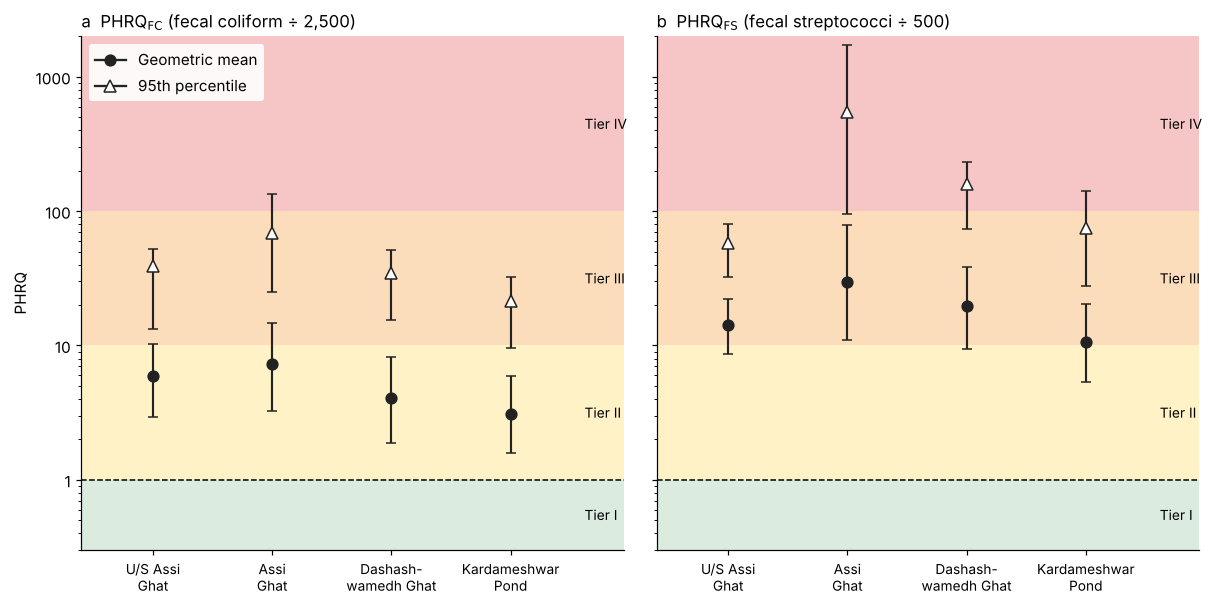

In [11]:
# ---- Fig. 3: GM and P95 of PHRQ with bootstrap intervals, on the tier scale ------------
bands = [(0.3, 1, "#DCEBE0", "Tier I"), (1, 10, "#FFF2C7", "Tier II"), (10, 100, "#FBDDBB", "Tier III"), (100, 2000, "#F6C6C6", "Tier IV")]
xlabels = ["U/S Assi\nGhat", "Assi\nGhat", "Dashash-\nwamedh Ghat", "Kardameshwar\nPond"]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.6), sharey=True)
for ax, key, title in zip(axes, ("FC", "FS"), ("a  PHRQ$_{\\mathrm{FC}}$ (fecal coliform ÷ 2,500)", "b  PHRQ$_{\\mathrm{FS}}$ (fecal streptococci ÷ 500)")):
    for lo, hi, c, lab in bands:
        ax.axhspan(lo, hi, color=c, lw=0)
        ax.text(3.62, np.sqrt(lo * hi), lab, va="center", fontsize=9)
    ax.axhline(1, color="k", ls="--", lw=1)
    for i, s in enumerate(SITE):
        d = PH[(key, s)]
        ax.errorbar(i, d["gm"], yerr=[[d["gm"] - d["gm_lo"]], [d["gm_hi"] - d["gm"]]], fmt="o", color=COL["ink"], ms=7, capsize=3.5, lw=1.4)
        ax.errorbar(i, d["p95"], yerr=[[d["p95"] - d["p95_lo"]], [d["p95_hi"] - d["p95"]]], fmt="^", color=COL["ink"], mfc="white", ms=8, capsize=3.5, lw=1.4)
    ax.set_yscale("log"); ax.set_ylim(0.3, 2000); ax.set_xlim(-0.6, 3.95)
    ax.set_xticks(range(4)); ax.set_xticklabels(xlabels, fontsize=9); ax.set_title(title, loc="left", fontsize=11)
axes[0].set_ylabel("PHRQ"); plain_ticks(axes[0], "y", [1, 10, 100, 1000])
axes[0].legend(handles=[Line2D([], [], marker="o", color=COL["ink"], ls="-", ms=7, label="Geometric mean"),
                        Line2D([], [], marker="^", color=COL["ink"], mfc="white", ls="-", ms=8, label="95th percentile")],
               loc="upper left", frameon=True, facecolor="white", framealpha=0.9, edgecolor="none")
fig.tight_layout()
save_fig(fig, "Fig3_PHRQ_by_site")

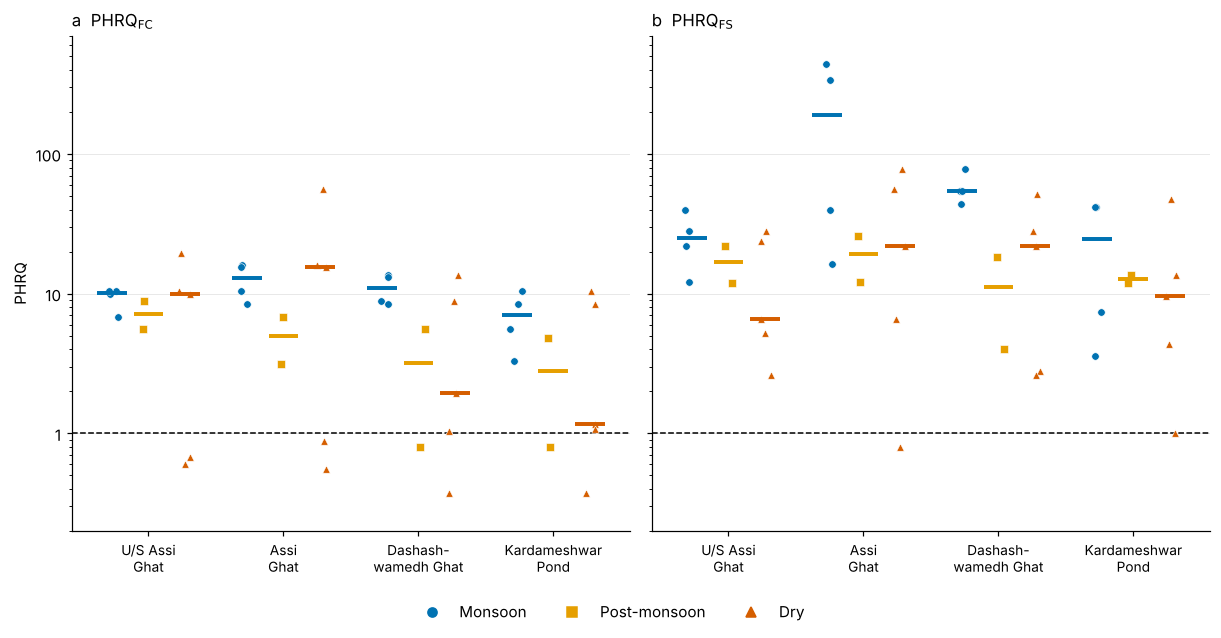

Bars = seasonal medians. Samples above the dashed line (PHRQ > 1) exceed the CPCB limit.


In [12]:
# PHRQ of every sample by site and season ---------------------
rng_j = np.random.default_rng(SEED + 7)
offs = {"Monsoon": -0.27, "Post-monsoon": 0.0, "Dry": 0.27}
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.6), sharey=True)
for ax, col_, title in zip(axes, ("phrq_fc", "phrq_fs"), ("a  PHRQ$_{\\mathrm{FC}}$", "b  PHRQ$_{\\mathrm{FS}}$")):
    for i, s in enumerate(SITE):
        for se in SEASONS:
            g = df[(df.site_code == s) & (df.season == se)][col_].values; c, m = SEASON_STYLE[se]
            ax.scatter(i + offs[se] + rng_j.uniform(-0.05, 0.05, len(g)), g, c=c, marker=m, s=24, edgecolor="white", lw=0.4, zorder=3)
            ax.hlines(np.median(g), i + offs[se] - 0.11, i + offs[se] + 0.11, color=c, lw=2.6, zorder=4)
    ax.axhline(1, color="k", ls="--", lw=1); ax.set_yscale("log"); ax.set_ylim(0.2, 700)
    ax.grid(axis="y", color="#e6e6e6", lw=0.6)
    ax.set_xticks(range(4)); ax.set_xticklabels(xlabels, fontsize=9); ax.set_title(title, loc="left", fontsize=11)
axes[0].set_ylabel("PHRQ"); plain_ticks(axes[0], "y", [1, 10, 100])
fig.legend(handles=[Line2D([], [], color=SEASON_STYLE[s][0], marker=SEASON_STYLE[s][1], ls="", ms=6, label=s) for s in SEASONS],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_fig(fig, "FigE5_PHRQ_per_sample")
print("Bars = seasonal medians. Samples above the dashed line (PHRQ > 1) exceed the CPCB limit.")

### International grades (second part of Table S3)
The same samples are graded against two international schemes, using the *enterococci* and *E. coli* distributions of each site (log-normal percentiles: P95 = 10^(μ+1.65σ), P90 = 10^(μ+1.282σ)):

* **WHO** recreational-water category from the enterococci P95: A ≤ 40, B ≤ 200, C ≤ 500, D > 500 per 100 mL.
* **EU inland bathing-water class**: *Excellent* (enterococci P95 ≤ 200 and *E. coli* P95 ≤ 500); *Good* (≤ 400 and ≤ 1,000 at P95); *Sufficient* (≤ 330 and ≤ 900 at P90); otherwise *Poor*.
* **US EPA**: the site GM divided by the criteria of 126 (*E. coli*) and 35 (enterococci) per 100 mL.

In [13]:
rows = []
for s, name in SITE.items():
    ec = np.log10(df.loc[df.site_code == s, "e_coli"]); en = np.log10(df.loc[df.site_code == s, "enterococci"])
    gm_e, gm_n = 10 ** ec.mean(), 10 ** en.mean()
    p95_n, p90_n = 10 ** (en.mean() + 1.65 * en.std(ddof=1)), 10 ** (en.mean() + 1.282 * en.std(ddof=1))
    p95_e, p90_e = 10 ** (ec.mean() + 1.65 * ec.std(ddof=1)), 10 ** (ec.mean() + 1.282 * ec.std(ddof=1))
    who = "A" if p95_n <= 40 else "B" if p95_n <= 200 else "C" if p95_n <= 500 else "D"
    eu = ("Excellent" if p95_n <= 200 and p95_e <= 500 else "Good" if p95_n <= 400 and p95_e <= 1000
          else "Sufficient" if p90_n <= 330 and p90_e <= 900 else "Poor")
    rows.append({"Site": name, "E. coli GM": sig(gm_e), "GM ÷ 126": sig(gm_e / 126), "Enterococci GM": sig(gm_n),
                 "GM ÷ 35": sig(gm_n / 35), "Enterococci P95": sig(p95_n), "P95 ÷ 500": sig(p95_n / 500),
                 "WHO category": who, "EU class": eu})
grades = pd.DataFrame(rows).set_index("Site")
display(grades); save_table(grades, "Table_S3_part2_international_grades")
print("Paper: E. coli GM ÷ 126 = 26, 43, 22, 23; enterococci GM ÷ 35 = 62, 96, 100, 47; P95 ÷ 500 = 20, 65, 49, 19; every site WHO D and EU Poor.")

,E. coli GM,GM ÷ 126,Enterococci GM,GM ÷ 35,Enterococci P95,P95 ÷ 500,WHO category,EU class
Site,,,,,,,,
U/S Assi Ghat,"3,200",26,"2,200",62,"9,900",20,D,Poor
Assi Ghat,"5,400",43,"3,400",96,"33,000",65,D,Poor
Dashashwamedh Ghat,"2,800",22,"3,500",100,"24,000",49,D,Poor
Kardameshwar Pond,"2,900",23,"1,600",47,"9,400",19,D,Poor


Paper: E. coli GM ÷ 126 = 26, 43, 22, 23; enterococci GM ÷ 35 = 62, 96, 100, 47; P95 ÷ 500 = 20, 65, 49, 19; every site WHO D and EU Poor.


## 5 · The risk model: from an indicator concentration to the probability of illness

For one bathing **event**, the model (Supplementary Table S2) chains five steps, repeated in a Monte Carlo simulation with random inputs:

1. **Indicator concentration** *C* (*E. coli* or enterococci, MPN per 100 mL) – observed, drawn from a fitted Gamma distribution, or predicted from the FC regression.
2. **Pathogen concentration** (per mL) = *C*/100 × **ratio** × **κ**, where the *ratio* (pathogen : indicator, drawn uniformly between published bounds) differs for each of four reference pathogens – *Campylobacter*, norovirus GI, human adenovirus and *Giardia* – and **κ** is a scaling factor calibrated in Step 7.
3. **Dose** = pathogen concentration × **volume swallowed** per event *V* (mL).
4. **Infection probability** from a dose–response model: exact beta-Poisson *P* = 1 − ₁F₁(α; α+β; −*D*) for *Campylobacter* and norovirus, exponential *P* = 1 − exp(−*rD*) for adenovirus and *Giardia*.
5. **Illness probability** = infection probability × P(illness | infection); the four pathogens are combined as 1 − ∏(1 − *P*ᵢₗₗ,ⱼ), assuming independence.

In [14]:
# ---- Model inputs (Supplementary Table S2) ----------------------------------------------
VOL_BASE  = (10.0, 35.0, 50.0)     # mL per event, triangular (min, mode, max)
VOL_HEAVY = (35.0, 100.0, 200.0)   # heavier-ingestion scenario (an assumption, not from a specific study)
KAPPA = {"ecoli": 9.0, "ent": 2.0}  # scaling factors (calibrated in Step 7)
LABEL = {"ecoli": "E. coli pathway", "ent": "Enterococci pathway"}
PATHOGENS = ["noro", "adeno", "giar", "camp"]
NAMES = {"noro": "Norovirus GI", "adeno": "Adenovirus", "giar": "Giardia lamblia", "camp": "Campylobacter"}
# pathogen : indicator ratios (per gene-copy equivalent), uniform between the bounds
RATIO = {
    "ecoli": {"camp": (2.04e-06, 1.42e-05), "adeno": (2.83e-06, 1.02e-04), "noro": (8.95e-06, 2.57e-04), "giar": (1.62e-04, 2.25e-03)},
    "ent":   {"camp": (2.25e-05, 6.17e-04), "adeno": (1.23e-04, 1.13e-03), "noro": (3.89e-04, 2.83e-03), "giar": (1.79e-03, 9.77e-02)},
}

# ---- dose-response: exact beta-Poisson tabulated with mpmath on a 4,001-point log grid ------
mp.mp.dps = 30
DOSE_GRID = np.logspace(-9, 7, 4001)
_BP = {}
def bp_table(alpha, beta):
    key = (alpha, beta)
    if key not in _BP:
        _BP[key] = np.array([float(1 - mp.hyp1f1(alpha, alpha + beta, -mp.mpf(float(d)))) for d in DOSE_GRID])
    return _BP[key]
def bp_infect(alpha, beta):
    tab = bp_table(alpha, beta)
    return lambda dose: np.interp(np.log10(np.clip(dose, 1e-9, 1e7)), np.log10(DOSE_GRID), tab)
def exp_infect(r):
    return lambda dose: 1.0 - np.exp(-r * dose)

# infection model and illness-given-infection for each pathogen (the "primary" parameter set)
PRIMARY = {
    "camp":  dict(infect=bp_infect(0.1453, 8.007), ill=("uniform", 0.1, 0.6), desc="exact beta-Poisson, α = 0.1453, β = 8.007 (C. jejuni)"),
    "adeno": dict(infect=exp_infect(0.4172),       ill=("const", 0.5),        desc="exponential, r = 0.4172"),
    "noro":  dict(infect=bp_infect(0.04, 0.055),   ill=("uniform", 0.3, 0.8), desc="exact beta-Poisson, α = 0.04, β = 0.055 (genome copies)"),
    "giar":  dict(infect=exp_infect(0.0199),       ill=("uniform", 0.2, 0.7), desc="exponential, r = 0.0199"),
}
rows = []
for p in ["camp", "noro", "adeno", "giar"]:
    ill = PRIMARY[p]["ill"]
    rows.append({"Pathogen": NAMES[p], "Infection (dose–response)": PRIMARY[p]["desc"],
                 "Illness | infection": f"U({ill[1]}, {ill[2]})" if ill[0] == "uniform" else f"{ill[1]} (fixed)",
                 "Ratio to E. coli": f"{RATIO['ecoli'][p][0]:.2e} – {RATIO['ecoli'][p][1]:.2e}",
                 "Ratio to enterococci": f"{RATIO['ent'][p][0]:.2e} – {RATIO['ent'][p][1]:.2e}"})
table_s2 = pd.DataFrame(rows).set_index("Pathogen")
display(table_s2); save_table(table_s2, "Table_S2_pathogen_inputs")
print(f"Ingested volume per event: triangular{VOL_BASE} mL (baseline);  triangular{VOL_HEAVY} mL (heavier scenario).  kappa: {KAPPA}")

,Infection (dose–response),Illness | infection,Ratio to E. coli,Ratio to enterococci
Pathogen,,,,
Campylobacter,"exact beta-Poisson, α = 0.1453, β = 8.007 (C. ...","U(0.1, 0.6)",2.04e-06 – 1.42e-05,2.25e-05 – 6.17e-04
Norovirus GI,"exact beta-Poisson, α = 0.04, β = 0.055 (genom...","U(0.3, 0.8)",8.95e-06 – 2.57e-04,3.89e-04 – 2.83e-03
Adenovirus,"exponential, r = 0.4172",0.5 (fixed),2.83e-06 – 1.02e-04,1.23e-04 – 1.13e-03
Giardia lamblia,"exponential, r = 0.0199","U(0.2, 0.7)",1.62e-04 – 2.25e-03,1.79e-03 – 9.77e-02


Ingested volume per event: triangular(10.0, 35.0, 50.0) mL (baseline);  triangular(35.0, 100.0, 200.0) mL (heavier scenario).  kappa: {'ecoli': 9.0, 'ent': 2.0}


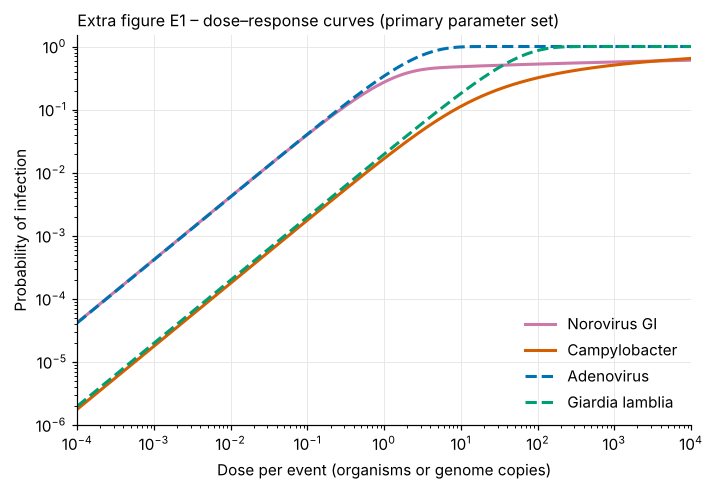

In [15]:
# ---- Extra figure E1: infection probability versus dose for the four pathogens --------
dose = np.logspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for p, c, ls in [("noro", COL["pink"], "-"), ("camp", COL["vermillion"], "-"), ("adeno", COL["blue"], "--"), ("giar", COL["green"], "--")]:
    ax.plot(dose, PRIMARY[p]["infect"](dose), color=c, ls=ls, lw=2, label=f"{NAMES[p]}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5); ax.set_xlim(1e-4, 1e4)
ax.set_xlabel("Dose per event (organisms or genome copies)"); ax.set_ylabel("Probability of infection")
ax.grid(color="#e6e6e6", lw=0.6); ax.legend(loc="lower right")
ax.set_title("Extra figure E1 – dose–response curves (primary parameter set)", loc="left", fontsize=10.5)
save_fig(fig, "FigE1_dose_response_curves")

### Volume swallowed per event
The ingested volume is the one exposure input taken from the literature on swimmers. The **baseline** is a triangular distribution (minimum 10, mode 35, maximum 50 mL; mean ≈ 32 mL) anchored to biomarker-based measurements of water ingestion by swimmers (Dufour et al. 2006) and to the wider swimming-ingestion literature (Dorevitch et al. 2011; Dufour et al. 2017; Suppes et al. 2014). It describes *central-tendency, single-event* ingestion; substantially higher 95th-percentile volumes have been reported for benchmark derivation (WHO 2021; Schets et al. 2011; DeFlorio-Barker et al. 2018). The **heavier scenario** (35, 100, 200 mL) is a sensitivity case whose bounds are an assumption of this study.

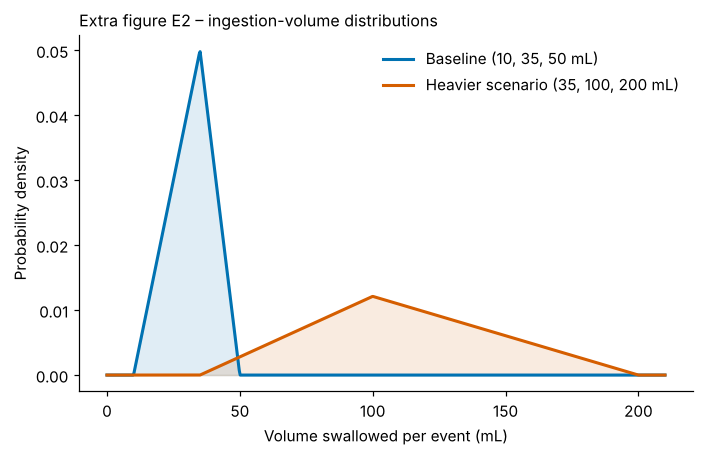

,min,mode,max,mean,median,5th pct,95th pct
Baseline,10.0,35.0,50.0,31.7,32.4,17.1,44.5
Heavier,35.0,100.0,200.0,111.7,109.2,58.2,171.3


In [16]:
# ---- Extra figure E2: the two ingestion distributions ------------------------------------
def tri_dist(v):
    lo, mode, hi = v
    return stats.triang((mode - lo) / (hi - lo), loc=lo, scale=hi - lo)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
x = np.linspace(0, 210, 600)
for v, c, lab in [(VOL_BASE, COL["blue"], "Baseline (10, 35, 50 mL)"), (VOL_HEAVY, COL["vermillion"], "Heavier scenario (35, 100, 200 mL)")]:
    d = tri_dist(v); ax.plot(x, d.pdf(x), color=c, lw=2, label=lab); ax.fill_between(x, d.pdf(x), color=c, alpha=0.12)
ax.set_xlabel("Volume swallowed per event (mL)"); ax.set_ylabel("Probability density"); ax.legend()
ax.set_title("Extra figure E2 – ingestion-volume distributions", loc="left", fontsize=10.5)
save_fig(fig, "FigE2_ingestion_distributions")
vt = pd.DataFrame({name: {"min": v[0], "mode": v[1], "max": v[2], "mean": tri_dist(v).mean(), "median": tri_dist(v).median(),
                           "5th pct": tri_dist(v).ppf(0.05), "95th pct": tri_dist(v).ppf(0.95)}
                   for name, v in [("Baseline", VOL_BASE), ("Heavier", VOL_HEAVY)]}).T.round(1)
display(vt)

### The Monte Carlo engine
The next cell defines the functions used by every later step. To make curves smooth and comparisons fair, one set of **common random numbers** (`Draws`) is reused for all evaluations: the same random volume, ratio and illness fractions are used at every concentration. `combined_illness()` returns the combined illness probability for any array of indicator concentrations, together with the pathogen-specific illness probabilities and doses.

In [17]:
def tri_ppf(u, lo, mode, hi):
    """inverse CDF of the triangular distribution (so uniform draws -> volumes)"""
    fc = (mode - lo) / (hi - lo)
    return np.where(u < fc, lo + np.sqrt(u * (hi - lo) * (mode - lo)), hi - np.sqrt((1 - u) * (hi - lo) * (hi - mode)))

class Draws:
    """common random numbers used by all model evaluations"""
    def __init__(self, n, seed):
        rng = np.random.default_rng(seed)
        self.n = n
        self.z = rng.standard_normal(n)                       # indicator variability / regression residual
        self.u_vol = rng.random(n)                            # ingestion volume
        self.u_ratio = {p: rng.random(n) for p in PATHOGENS}  # pathogen:indicator ratios
        self.u_ill = {p: rng.random(n) for p in PATHOGENS}    # illness given infection
        self.u_boot = rng.integers(0, 2 ** 31 - 1, n)         # which bootstrap regression refit

def illness_given_infection(rule, u, dose, scen="base"):
    kind = rule[0]
    if kind == "const": return rule[1]
    if kind == "uniform":
        lo, hi = rule[1], rule[2]
        return lo if scen == "ill_low" else hi if scen == "ill_high" else lo + (hi - lo) * u
    if kind == "pert":                                         # beta-PERT(min, mode, max)
        lo, mode, hi = rule[1:]
        a_, b_ = 1 + 4 * (mode - lo) / (hi - lo), 1 + 4 * (hi - mode) / (hi - lo)
        return lo + (hi - lo) * stats.beta.ppf(u, a_, b_)
    if kind == "dosedep":                                      # 1 - (1 + eta*D)^-r
        return 1 - (1 + rule[1] * dose) ** (-rule[2])
    raise ValueError(kind)

def combined_illness(ind_per100, pathway, vol, rn, kappa=None, spec=None, scen="base"):
    """Per-event illness for indicator concentrations `ind_per100` (array, MPN/100 mL).
    scen: base | ill_low | ill_high | ratio_min | ratio_max."""
    spec = PRIMARY if spec is None else spec
    k = KAPPA[pathway] if kappa is None else kappa
    V = tri_ppf(rn.u_vol, *vol)
    per, doses, comp = {}, {}, []
    for p in PATHOGENS:
        lo, hi = RATIO[pathway][p]
        ratio = lo if scen == "ratio_min" else hi if scen == "ratio_max" else lo + (hi - lo) * rn.u_ratio[p]
        dose = ind_per100 / 100.0 * ratio * k * V
        pill = spec[p]["infect"](dose) * illness_given_infection(spec[p]["ill"], rn.u_ill[p], dose, scen)
        per[p], doses[p] = pill, dose; comp.append(1.0 - pill)
    return 1.0 - np.prod(comp, axis=0), per, doses

def summ(x):
    return float(np.median(x)), float(np.percentile(x, 5)), float(np.percentile(x, 95))

# ---- regression with bootstrap uncertainty (used to predict E. coli / enterococci from FC) ----
def boot_regressions(data, B=B_REG, seed=SEED + 11):
    rng = np.random.default_rng(seed)
    x = np.log10(data.fecal_coliform.values); n = len(x)
    Y = {"ecoli": np.log10(data.e_coli.values), "ent": np.log10(data.enterococci.values)}
    idx = rng.integers(0, n, (B, n)); xs = x[idx]
    out = {}
    for k, y in Y.items():
        ys = y[idx]; xb, yb = xs.mean(1, keepdims=True), ys.mean(1, keepdims=True)
        b = ((xs - xb) * (ys - yb)).sum(1) / ((xs - xb) ** 2).sum(1); a = yb[:, 0] - b * xb[:, 0]
        s = np.sqrt(((ys - (a[:, None] + b[:, None] * xs)) ** 2).sum(1) / (n - 2))
        out[k] = np.c_[a, b, s]
    return out
BOOT = boot_regressions(df)

def predicted_indicator(phrq, pathway, rn, boot=BOOT):
    """E. coli or enterococci (per 100 mL) predicted from FC = PHRQ x 2,500, with regression + residual uncertainty"""
    a, b, s = boot[pathway][rn.u_boot % len(boot[pathway])].T
    return 10 ** (a + b * np.log10(phrq * FC_LIMIT) + s * rn.z)

def epa_relation(ecoli_per100):
    """US EPA relation: HCGI = -11.74 + 9.397 log10(E. coli) per 1,000; NGI = 4.5 x HCGI; probability = NGI/1000"""
    return 4.5 * (-11.74 + 9.397 * np.log10(ecoli_per100)) / 1000.0

rn_test = Draws(50_000, SEED)
ill_test, per_test, dose_test = combined_illness(np.full(50_000, 800.0), "ecoli", VOL_BASE, rn_test)
print("Engine test: E. coli = 800 per 100 mL (PHRQ_FC = 1) -> median combined illness %.3f (5th %.3f, 95th %.3f)" % summ(ill_test))
print("   median doses: " + ", ".join(f"{NAMES[p]} {np.median(dose_test[p]):.3g}" for p in PATHOGENS))

Engine test: E. coli = 800 per 100 mL (PHRQ_FC = 1) -> median combined illness 0.098 (5th 0.039, 95th 0.182)
   median doses: Norovirus GI 0.28, Adenovirus 0.111, Giardia lamblia 2.55, Campylobacter 0.0173


## 6 · Distribution fits for the site-level risk

For site- and season-level risk the observed *E. coli* and enterococci concentrations are summarised by a **Gamma distribution** fitted by maximum likelihood (location fixed at 0), so the model can sample concentrations that were not observed. We check the choice against **log-normal** and **Weibull** alternatives with the Akaike information criterion (AIC = 2*k* − 2 ln *L*, *k* = 2; lower is better) and a Kolmogorov–Smirnov (KS) test of the Gamma fit. Concentrations are expressed in 1,000 MPN per 100 mL.

In [18]:
rows = []
GAMMA = {}
for s, name in SITE.items():
    for col_, lab in [("e_coli", "E. coli"), ("enterococci", "Enterococci")]:
        x = df.loc[df.site_code == s, col_].values / 1000.0
        g = stats.gamma.fit(x, floc=0); GAMMA[(s, col_)] = (g[0], g[2])
        ll = {"Gamma": stats.gamma.logpdf(x, g[0], 0, g[2]).sum()}
        l_ = stats.lognorm.fit(x, floc=0); ll["Log-normal"] = stats.lognorm.logpdf(x, l_[0], 0, l_[2]).sum()
        w = stats.weibull_min.fit(x, floc=0); ll["Weibull"] = stats.weibull_min.logpdf(x, w[0], 0, w[2]).sum()
        aic = {k: 4 - 2 * v for k, v in ll.items()}; best = min(aic, key=aic.get)
        rows.append({"Site": name, "Indicator": lab, "Gamma shape": g[0], "Gamma rate": 1 / g[2], "AIC Gamma": aic["Gamma"],
                     "AIC log-normal": aic["Log-normal"], "AIC Weibull": aic["Weibull"], "Lowest AIC": best,
                     "Gamma − best": aic["Gamma"] - aic[best], "KS p (Gamma)": stats.kstest(x, "gamma", args=(g[0], 0, g[2])).pvalue})
fits = pd.DataFrame(rows).set_index(["Site", "Indicator"])
display(fits.round(3)); save_table(fits.round(4), "Extra_distribution_fits")
print(f"Gamma has the lowest AIC in {(fits['Lowest AIC'] == 'Gamma').sum()} of 8 series; largest AIC gap to the best model {fits['Gamma − best'].max():.2f}; smallest KS p = {fits['KS p (Gamma)'].min():.3f}")
print("Paper: lowest AIC in 4 of 8, within 0.7 units of the best in the rest, KS test does not reject Gamma for any series (all p > 0.25).")

Gamma shape  Gamma rate  AIC Gamma  \
Site               Indicator                                         
U/S Assi Ghat      E. coli            0.914       0.149     65.879   
                   Enterococci        1.679       0.558     48.709   
Assi Ghat          E. coli            0.893       0.086     77.382   
                   Enterococci        1.047       0.179     64.779   
Dashashwamedh Ghat E. coli            1.265       0.291     57.995   
                   Enterococci        1.107       0.189     64.826   
Kardameshwar Pond  E. coli            1.711       0.432     54.636   
                   Enterococci        1.249       0.483     46.595   

                                AIC log-normal  AIC Weibull  Lowest AIC  \
Site               Indicator                                              
U/S Assi Ghat      E. coli              68.010       65.908       Gamma   
                   Enterococci          49.426       48.847       Gamma   
Assi Ghat          E. coli              79.980       77.406       Gamma   
                   Enterococci          67.897       64.649     Weibull   
Dashashwamedh Ghat E. coli              61.709       57.495     Weibull   
                   Enterococci          65.288       64.861       Gamma   
Kardameshwar Pond  E. coli              56.611       54.034     Weibull   
                   Enterococci          46.386       46.804  Log-normal   

                                Gamma − best  KS p (Gamma)  
Site               Indicator                                
U/S Assi Ghat      E. coli             0.000         0.803  
                   Enterococci         0.000         0.858  
Assi Ghat          E. coli             0.000         0.562  
                   Enterococci         0.130         0.862  
Dashashwamedh Ghat E. coli             0.500         0.529  
                   Enterococci         0.000         0.933  
Kardameshwar Pond  E. coli             0.603         0.384  
                   Enterococci         0.209         0.263

Gamma has the lowest AIC in 4 of 8 series; largest AIC gap to the best model 0.60; smallest KS p = 0.263
Paper: lowest AIC in 4 of 8, within 0.7 units of the best in the rest, KS test does not reject Gamma for any series (all p > 0.25).


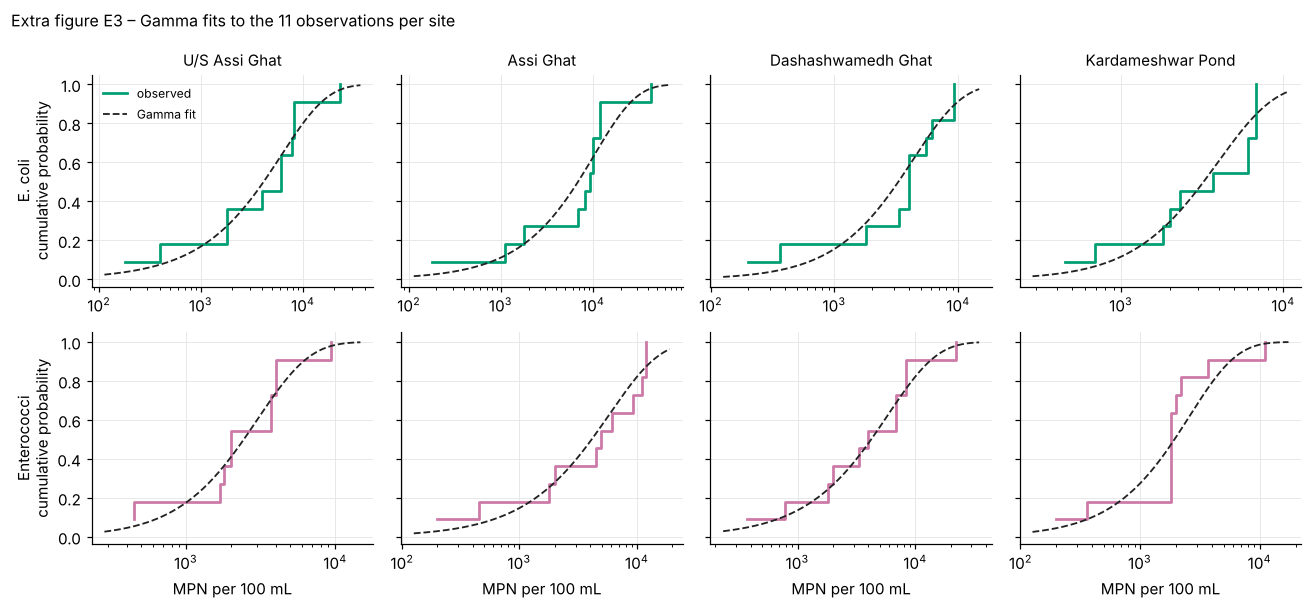

In [19]:
# ---- Extra figure E3: empirical versus fitted Gamma distribution functions ---------------
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharey=True)
for j, (s, name) in enumerate(SITE.items()):
    for i, (col_, lab, c) in enumerate([("e_coli", "E. coli", COL["green"]), ("enterococci", "Enterococci", COL["pink"])]):
        ax = axes[i, j]; x = np.sort(df.loc[df.site_code == s, col_].values)
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=c, lw=1.8, label="observed")
        sh, sc = GAMMA[(s, col_)]; xs = np.logspace(np.log10(x.min()) - 0.2, np.log10(x.max()) + 0.2, 200)
        ax.plot(xs, stats.gamma.cdf(xs / 1000, sh, 0, sc), color=COL["ink"], ls="--", lw=1.2, label="Gamma fit")
        ax.set_xscale("log"); ax.grid(color="#e6e6e6", lw=0.6)
        if i == 0: ax.set_title(name, fontsize=10)
        if j == 0: ax.set_ylabel(f"{lab}\ncumulative probability")
        if i == 1: ax.set_xlabel("MPN per 100 mL")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Extra figure E3 – Gamma fits to the 11 observations per site", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout()
save_fig(fig, "FigE3_gamma_fits")

## 7 · Calibrating the scaling factor κ and checking benchmark consistency

The pathogen:indicator ratios come from wastewater studies and carry large uncertainty, so the absolute level of risk is anchored to epidemiology. **κ** is chosen so that the model reproduces the **US EPA recreational-water criterion**: at a site whose *E. coli* geometric mean is 126 per 100 mL (or enterococci 35 per 100 mL) the *expected* illness probability per event is **0.036** (36 per 1,000). Concentrations at a real site vary from day to day, so the expectation is taken over a log-normal distribution centred on the criterion with the within-site SD of log₁₀ concentration (0.57 for *E. coli*, 0.50 for enterococci). κ is found by **root finding** (Brent's method), separately for the *E. coli* and enterococci pathways.

In [20]:
rn_cal = Draws(N_CAL, SEED + 5)
EPA_ANCHOR = {"ecoli": (126.0, 0.57), "ent": (35.0, 0.50)}   # criterion (GM per 100 mL), within-site SD of log10
EPA_TARGET = 0.036                                           # 36 illnesses per 1,000 swimmers

def expected_illness(pathway, kappa, vol=VOL_BASE, rn=rn_cal, spec=None):
    crit, sd = EPA_ANCHOR[pathway]
    ind = crit * 10 ** (sd * rn.z)                           # log-normal concentrations around the criterion
    return float(np.mean(combined_illness(ind, pathway, vol, rn, kappa=kappa, spec=spec)[0]))

t0 = time.time()
kappa_solved = {pw: brentq(lambda k: expected_illness(pw, k) - EPA_TARGET, 0.1, 100, xtol=1e-3) for pw in ("ecoli", "ent")}
print(f"Solved in {time.time() - t0:.0f} s with {N_CAL:,} draws")
for pw in ("ecoli", "ent"):
    print(f"  {LABEL[pw]:<20s} kappa = {kappa_solved[pw]:.2f}  -> rounded {KAPPA[pw]};  "
          f"expected illness with the rounded kappa = {expected_illness(pw, KAPPA[pw]):.4f} (target 0.036)")
print("Paper: kappa 8.97 -> 9.0 (E. coli) and 2.01 -> 2.0 (enterococci).")
check("kappa E. coli", kappa_solved["ecoli"], 8.97, 0.04); check("kappa enterococci", kappa_solved["ent"], 2.01, 0.04)

Solved in 4 s with 1,000,000 draws


  E. coli pathway      kappa = 8.91  -> rounded 9.0;  expected illness with the rounded kappa = 0.0363 (target 0.036)
  Enterococci pathway  kappa = 2.01  -> rounded 2.0;  expected illness with the rounded kappa = 0.0359 (target 0.036)
Paper: kappa 8.97 -> 9.0 (E. coli) and 2.01 -> 2.0 (enterococci).
  ✓ kappa E. coli: notebook 8.905  |  paper 8.97
  ✓ kappa enterococci: notebook 2.007  |  paper 2.01


True

### Benchmark consistency (Fig. 4)
Is a single κ credible beyond the anchor? We compare the model's predicted per-event illness with **seven published benchmarks**:
US EPA criteria set 1 (*E. coli* 126, enterococci 35; illness 0.036) and set 2 (100 and 30; 0.032), and the WHO category limits for enterococci (40, 200, 500 per 100 mL ↔ illness 0.010, 0.050, 0.10). For the EPA anchors the prediction is the *expected* illness over the log-normal distribution; for the WHO limits it is the *median* illness at the limit concentration.
Four scalings are compared: **C1** (published ratios unchanged, κ = 1), **C2** (ratios × 5.6 for both indicators, a literature factor), **C3** (× 5.6 for *E. coli*, × 1 for enterococci) and the **calibrated** κ (9.0 and 2.0). A ratio of 1 means the prediction equals the benchmark; the grey band is a factor of 2 either way.

In [21]:
rn_bm = Draws(300_000, SEED + 6)
ANCHORS = [("E. coli 100 (EPA set 2 GM)", "ecoli", 100, 0.032, "epa", 0.57),
           ("E. coli 126 (EPA set 1 GM) †", "ecoli", 126, 0.036, "epa", 0.57),
           ("Enterococci 30 (EPA set 2 GM)", "ent", 30, 0.032, "epa", 0.50),
           ("Enterococci 35 (EPA set 1 GM) †", "ent", 35, 0.036, "epa", 0.50),
           ("Enterococci 40 (WHO A limit)", "ent", 40, 0.010, "who", None),
           ("Enterococci 200 (WHO B limit)", "ent", 200, 0.050, "who", None),
           ("Enterococci 500 (WHO C limit)", "ent", 500, 0.10, "who", None)]
SCALINGS = {"C1": (1.0, 1.0), "C2": (5.6, 5.6), "C3": (5.6, 1.0), "Calibrated": (9.0, 2.0)}

def anchor_ratio(anchor, kappas, rn=rn_bm):
    label, pw, conc, bench, kind, sd = anchor
    k = kappas[0] if pw == "ecoli" else kappas[1]
    if kind == "epa":
        pred = float(np.mean(combined_illness(conc * 10 ** (sd * rn.z), pw, VOL_BASE, rn, kappa=k)[0]))
    else:
        pred = float(np.median(combined_illness(np.full(rn.n, float(conc)), pw, VOL_BASE, rn, kappa=k)[0]))
    return pred / bench

def median_at(phrq, pw, kappa, rn=rn_bm, vol=VOL_BASE, spec=None):
    return float(np.median(combined_illness(predicted_indicator(phrq, pw, rn), pw, vol, rn, kappa=kappa, spec=spec)[0]))

rows, ratio_mat = [], {}
for name, kap in SCALINGS.items():
    ratios = [anchor_ratio(a, kap) for a in ANCHORS]; ratio_mat[name] = ratios
    cross = 10 ** brentq(lambda lp: median_at(10 ** lp, "ecoli", kap[0]) - 0.036, np.log10(0.02), np.log10(50), xtol=1e-3)
    rows.append({"Scaling": name, "κ E. coli": kap[0], "κ enterococci": kap[1],
                 **{a[0].split(" (")[0] + (" †" if "†" in a[0] else ""): r for a, r in zip(ANCHORS, ratios)},
                 "Mean |log10 ratio|": float(np.mean(np.abs(np.log10(ratios)))),
                 "Median illness at PHRQ_FC = 1, E. coli path": median_at(1.0, "ecoli", kap[0]),
                 "Median illness at PHRQ_FC = 1, enterococci path": median_at(1.0, "ent", kap[1]),
                 "PHRQ_FC reaching 0.036": cross})
d28 = pd.DataFrame(rows).set_index("Scaling")
display(d28.round(3)); save_table(d28.round(4), "Extra_benchmark_consistency")

REP_D28 = {"C1": [0.118, 0.132, 0.51, 0.525, 1.106, 1.059, 1.225, 0.362, 0.0119, 0.1926, 3.4],
           "C2": [0.603, 0.66, 2.357, 2.372, 5.895, 4.727, 4.227, 0.46, 0.0625, 0.535, 0.53],
           "C3": [0.603, 0.66, 0.51, 0.525, 1.106, 1.059, 1.225, 0.161, 0.0625, 0.1926, 0.53],
           "Calibrated": [0.92, 0.999, 0.97, 0.991, 2.188, 2.01, 2.169, 0.148, 0.0961, 0.3181, 0.32]}
worst = max(abs(m / r - 1) for k in REP_D28 for m, r in zip(d28.loc[k].values[2:], REP_D28[k]))
worst_d28 = worst

,κ E. coli,κ enterococci,E. coli 100,E. coli 126 †,Enterococci 30,Enterococci 35 †,Enterococci 40,Enterococci 200,Enterococci 500,Mean |log10 ratio|,"Median illness at PHRQ_FC = 1, E. coli path","Median illness at PHRQ_FC = 1, enterococci path",PHRQ_FC reaching 0.036
Scaling,,,,,,,,,,,,,
C1,1.0,1.0,0.120,0.133,0.515,0.529,1.107,1.061,1.227,0.360,0.012,0.191,3.430
C2,5.6,5.6,0.611,0.668,2.372,2.386,5.903,4.738,4.235,0.459,0.062,0.534,0.538
C3,5.6,1.0,0.611,0.668,0.515,0.529,1.107,1.061,1.227,0.159,0.062,0.191,0.538
Calibrated,9.0,2.0,0.931,1.010,0.978,0.998,2.191,2.014,2.174,0.147,0.096,0.317,0.323


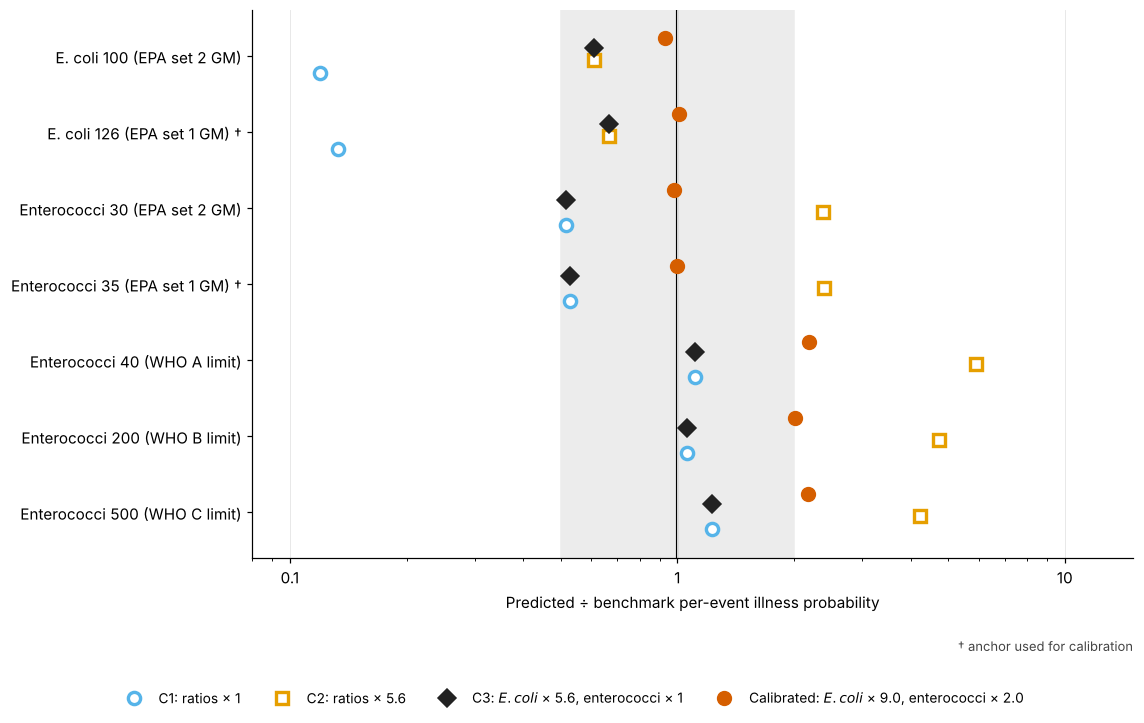

In [22]:
# ---- Fig. 4: predicted ÷ benchmark per-event illness for the seven anchors ---------------
style = {"C1": dict(marker="o", mfc="white", mec=COL["sky"], mew=2.2, color=COL["sky"], ms=8, label="C1: ratios × 1"),
         "C2": dict(marker="s", mfc="white", mec=COL["orange"], mew=2.2, color=COL["orange"], ms=8, label="C2: ratios × 5.6"),
         "C3": dict(marker="D", mfc=COL["ink"], mec=COL["ink"], color=COL["ink"], ms=8, label="C3: $E. coli$ × 5.6, enterococci × 1"),
         "Calibrated": dict(marker="o", mfc=COL["vermillion"], mec=COL["vermillion"], color=COL["vermillion"], ms=9,
                            label="Calibrated: $E. coli$ × 9.0, enterococci × 2.0")}
dy = {"Calibrated": 0.24, "C3": 0.11, "C2": -0.05, "C1": -0.22}
fig, ax = plt.subplots(figsize=(10.5, 6.4))
ax.axvspan(0.5, 2, color="#ececec", zorder=0); ax.axvline(1, color="k", lw=1.4, zorder=1)
for i, a in enumerate(ANCHORS):
    y = len(ANCHORS) - 1 - i
    for name in ("C1", "C2", "C3", "Calibrated"):
        ax.plot(ratio_mat[name][i], y + dy[name], ls="", zorder=3, **{k: v for k, v in style[name].items() if k != "label"})
ax.set_yticks(range(len(ANCHORS))); ax.set_yticklabels([a[0] for a in ANCHORS][::-1], fontsize=10)
ax.set_xscale("log"); ax.set_xlim(0.08, 15); ax.set_ylim(-0.6, len(ANCHORS) - 0.4)
ax.set_xticks([0.1, 1, 10]); ax.set_xticklabels(["0.1", "1", "10"]); ax.grid(axis="x", color="#e6e6e6", lw=0.6)
ax.set_xlabel("Predicted ÷ benchmark per-event illness probability")
ax.text(1.0, -0.17, "† anchor used for calibration", transform=ax.transAxes, ha="right", fontsize=8.5, color="#444")
fig.legend(handles=[Line2D([], [], ls="", **s) for s in style.values()], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03), fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, "Fig4_benchmark_consistency")

## 8 · Per-event illness at the monitored sites

### 8a · Site and season (Fig. 5a, Table S4)
For each site (and for each season, pooling the four sites) the observed *E. coli* and enterococci concentrations are replaced by the fitted **Gamma** distribution (Step 6), 100,000 concentrations are drawn, and the model of Step 5 is run with the calibrated κ. The result is the probability of illness for **one bathing event**: median and 5th–95th percentile over all sources of uncertainty (concentration, ratio, volume, illness fraction). Two pathways are reported, one driven by *E. coli* (κ = 9.0) and one by enterococci (κ = 2.0). Benchmarks: US EPA 0.036 and WHO 0.10.

In [23]:
rn_site = Draws(N_SITE, SEED + 21)
rng_g = np.random.default_rng(SEED + 22)
groups = [(name, dict(site_code=s)) for s, name in SITE.items()] + [(se, dict(season=se)) for se in SEASONS]
REP_SITE = {"U/S Assi Ghat": ((0.320, .0280, .688), (0.525, .155, .787)), "Assi Ghat": ((0.423, .0432, .763), (0.617, .135, .835)),
            "Dashashwamedh Ghat": ((0.278, .0398, .608), (0.621, .151, .835)), "Kardameshwar Pond": ((0.278, .0559, .573), (0.478, .0918, .773)),
            "Monsoon": ((0.406, .177, .641), (0.679, .346, .844)), "Post-monsoon": ((0.284, .0840, .543), (0.508, .277, .726)),
            "Dry": ((0.290, .00670, .721), (0.466, .0520, .786))}
site_res, rows = {}, []
for gname, where in groups:
    sub = df
    for k, v in where.items(): sub = sub[sub[k] == v]
    for pw, col_ in (("ecoli", "e_coli"), ("ent", "enterococci")):
        sh, _, sc = stats.gamma.fit(sub[col_].values / 1000.0, floc=0)
        ind = rng_g.gamma(sh, sc, N_SITE) * 1000.0
        comb, per, _ = combined_illness(ind, pw, VOL_BASE, rn_site)
        m = summ(comb); site_res[(gname, pw)] = m
        rows.append({"Site or season": gname, "Pathway": LABEL[pw].replace(" pathway", ""),
                     **{NAMES[p]: float(np.median(per[p])) for p in ["noro", "adeno", "giar", "camp"]},
                     "Combined median": m[0], "5th": m[1], "95th": m[2]})
table_s4 = pd.DataFrame(rows).set_index(["Site or season", "Pathway"])
display(table_s4.round(4)); save_table(table_s4.round(5), "Table_S4_illness_by_site_season")
worst = max(abs(site_res[(g, pw)][0] / REP_SITE[g][i][0] - 1) for g in REP_SITE for i, pw in enumerate(("ecoli", "ent")))
worst_s4 = worst

Norovirus GI  Adenovirus  Giardia lamblia  \
Site or season     Pathway                                                  
U/S Assi Ghat      E. coli            0.1470      0.0868           0.0817   
                   Enterococci        0.1869      0.1408           0.2644   
Assi Ghat          E. coli            0.1769      0.1368           0.1270   
                   Enterococci        0.2093      0.2122           0.3089   
Dashashwamedh Ghat E. coli            0.1345      0.0724           0.0678   
                   Enterococci        0.2115      0.2174           0.3127   
Kardameshwar Pond  E. coli            0.1353      0.0733           0.0683   
                   Enterococci        0.1706      0.1151           0.2332   
Monsoon            E. coli            0.1846      0.1386           0.1242   
                   Enterococci        0.2345      0.2877           0.3615   
Post-monsoon       E. coli            0.1392      0.0781           0.0718   
                   Enterococci        0.1896      0.1359           0.2687   
Dry                E. coli            0.1355      0.0726           0.0696   
                   Enterococci        0.1653      0.1092           0.2228   

                                Campylobacter  Combined median     5th    95th  
Site or season     Pathway                                                      
U/S Assi Ghat      E. coli             0.0004           0.3191  0.0282  0.6870  
                   Enterococci         0.0021           0.5234  0.1552  0.7851  
Assi Ghat          E. coli             0.0007           0.4194  0.0438  0.7625  
                   Enterococci         0.0034           0.6161  0.1369  0.8338  
Dashashwamedh Ghat E. coli             0.0004           0.2793  0.0396  0.6057  
                   Enterococci         0.0035           0.6200  0.1514  0.8343  
Kardameshwar Pond  E. coli             0.0004           0.2781  0.0567  0.5734  
                   Enterococci         0.0016           0.4762  0.0902  0.7741  
Monsoon            E. coli             0.0007           0.4069  0.1763  0.6410  
                   Enterococci         0.0052           0.6781  0.3476  0.8440  
Post-monsoon       E. coli             0.0004           0.2849  0.0838  0.5435  
                   Enterococci         0.0020           0.5074  0.2757  0.7256  
Dry                E. coli             0.0004           0.2889  0.0065  0.7196  
                   Enterococci         0.0015           0.4636  0.0505  0.7840

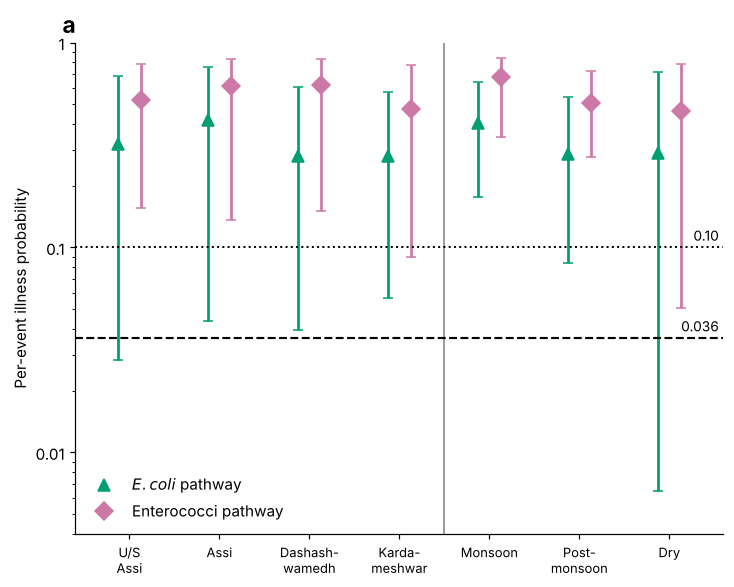

In [24]:
# ---- Fig. 5a: median and 5th-95th percentile by site and season ---------------------------
labels = ["U/S\nAssi", "Assi", "Dashash-\nwamedh", "Karda-\nmeshwar", "Monsoon", "Post-\nmonsoon", "Dry"]
names = list(SITE.values()) + SEASONS
fig, ax = plt.subplots(figsize=(7.6, 5.8))
for i, g in enumerate(names):
    for pw, c, mk, off in (("ecoli", COL["green"], "^", -0.13), ("ent", COL["pink"], "D", 0.13)):
        m, lo, hi = site_res[(g, pw)]
        ax.errorbar(i + off, m, yerr=[[m - lo], [hi - m]], fmt=mk, color=c, ms=8, capsize=3.5, lw=1.8)
ax.axvline(3.5, color="gray", lw=1)
ax.axhline(0.10, color="k", ls=":", lw=1.3); ax.axhline(0.036, color="k", ls="--", lw=1.4)
ax.text(6.55, 0.108, "0.10", ha="right", fontsize=9); ax.text(6.55, 0.039, "0.036", ha="right", fontsize=9)
ax.set_yscale("log"); ax.set_ylim(0.004, 1.0); ax.set_xlim(-0.6, 6.6); plain_ticks(ax, "y", [0.01, 0.1, 1])
ax.set_xticks(range(7)); ax.set_xticklabels(labels, fontsize=8.5); ax.set_ylabel("Per-event illness probability")
ax.legend(handles=[Line2D([], [], marker="^", color=COL["green"], ls="", ms=8, label="$E. coli$ pathway"),
                   Line2D([], [], marker="D", color=COL["pink"], ls="", ms=8, label="Enterococci pathway")], loc="lower left")
ax.text(-0.02, 1.02, "a", transform=ax.transAxes, fontsize=15, fontweight="bold")
save_fig(fig, "Fig5a_illness_by_site_and_season")

### 8b · Every sample (Fig. 5b)
Using each **observed** *E. coli* concentration directly (no Gamma fit), the model is run 20,000 times per sample (*E. coli* pathway, κ = 9.0), giving a median per-event illness for each of the 44 samples. Fig. 5b follows the four sites through the year; the dip in February 2026 corresponds to the lowest concentrations of the study.

Median per-event illness, E. coli pathway: range 0.024–0.741; above 0.036 in 41 of 44 samples, above 0.10 in 37
Lowest: 0.024 at U/S Assi Ghat on 2026-02-13 (E. coli = 180 per 100 mL)


,Date,Site,E. coli,Enterococci,Illness (E. coli path),Illness (enterococci path)
0,2025-06-17,U/S Assi Ghat,6100,4000,0.4137,0.6244
1,2025-06-17,Assi Ghat,12000,11000,0.5528,0.7434
2,2025-06-17,Dashashwamedh Ghat,9300,8300,0.5009,0.7181
3,2025-06-17,Kardameshwar Pond,6800,1800,0.4362,0.4757
4,2025-07-15,U/S Assi Ghat,8200,3700,0.4750,0.6116
5,2025-07-15,Assi Ghat,10000,12000,0.5158,0.7500
6,2025-07-15,Dashashwamedh Ghat,4000,6800,0.3297,0.6971
7,2025-07-15,Kardameshwar Pond,6100,1800,0.4137,0.4757


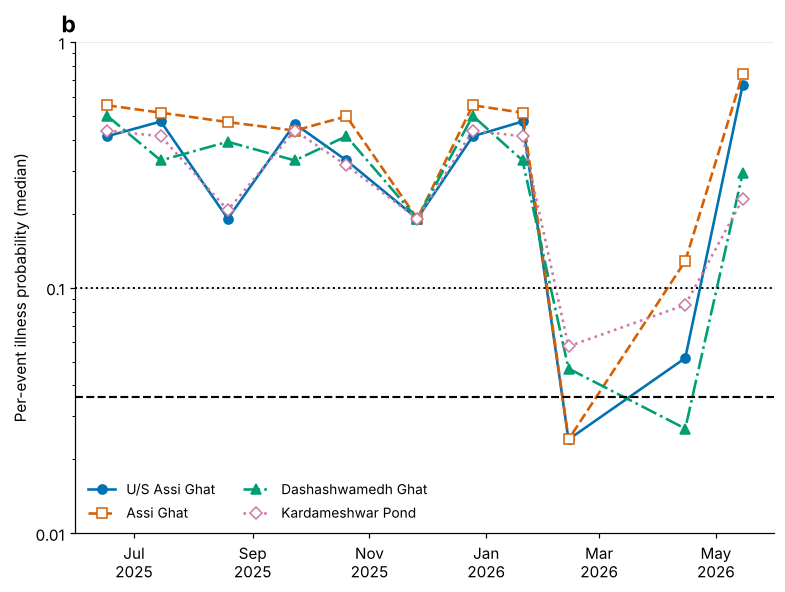

In [25]:
rn_s = Draws(N_SAMPLE, SEED + 23)
df["illness_ecoli_path"] = [float(np.median(combined_illness(np.full(N_SAMPLE, v), "ecoli", VOL_BASE, rn_s)[0])) for v in df.e_coli]
df["illness_ent_path"] = [float(np.median(combined_illness(np.full(N_SAMPLE, v), "ent", VOL_BASE, rn_s)[0])) for v in df.enterococci]
print(f"Median per-event illness, E. coli pathway: range {df.illness_ecoli_path.min():.3f}–{df.illness_ecoli_path.max():.3f}; "
      f"above 0.036 in {(df.illness_ecoli_path > 0.036).sum()} of 44 samples, above 0.10 in {(df.illness_ecoli_path > 0.10).sum()}")
low = df.loc[df.illness_ecoli_path.idxmin()]
print(f"Lowest: {low.illness_ecoli_path:.3f} at {low.site_name} on {low.date.date()} (E. coli = {low.e_coli:,.0f} per 100 mL)")
tbl = df[["date", "site_name", "e_coli", "enterococci", "illness_ecoli_path", "illness_ent_path"]].copy()
tbl["date"] = tbl.date.dt.strftime("%Y-%m-%d"); tbl.columns = ["Date", "Site", "E. coli", "Enterococci", "Illness (E. coli path)", "Illness (enterococci path)"]
display(tbl.round(4).head(8)); save_table(tbl.round(5), "Extra_sample_level_illness", index=False)

fig, ax = plt.subplots(figsize=(8.2, 5.8))
for code_, name in SITE.items():
    c, m, ls, filled = SITE_STYLE[code_]; g = df[df.site_code == code_].sort_values("date")
    ax.plot(g.date, g.illness_ecoli_path, color=c, marker=m, ls=ls, ms=6, lw=1.7, mfc=c if filled else "white", label=name)
ax.axhline(0.10, color="k", ls=":", lw=1.3); ax.axhline(0.036, color="k", ls="--", lw=1.4)
ax.set_yscale("log"); ax.set_ylim(0.01, 1.0); plain_ticks(ax, "y", [0.01, 0.1, 1]); ax.set_ylabel("Per-event illness probability (median)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[7, 9, 11, 1, 3, 5]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: mdates.num2date(v).strftime("%b\n%Y")))
ax.grid(axis="y", color="#e9e9e9", lw=0.6); ax.legend(loc="lower left", ncol=2, fontsize=9)
ax.text(-0.02, 1.02, "b", transform=ax.transAxes, fontsize=15, fontweight="bold")
save_fig(fig, "Fig5b_illness_per_sample")

## 9 · The PHRQ-to-risk map (Fig. 6, Table S5 A)

The final product links the regulatory number to health risk. For any PHRQ (a fecal-coliform concentration = PHRQ × 2,500):

1. predict the *E. coli* and enterococci concentration from FC with the regressions of Step 3 (using the 3,000 **bootstrap refits** and the residual scatter, so both parameter and sample-to-sample uncertainty are included);
2. run the risk model of Step 5 (50,000 draws, calibrated κ);
3. repeat on an 84-point log grid from PHRQ 0.2 to 100.

The curves give the median and 5th–95th percentile of per-event illness; the black dotted line is the **US EPA** relation, HCGI = −11.74 + 9.397 log₁₀(*E. coli*) per 1,000 with NGI = 4.5 × HCGI, extrapolated beyond the concentrations on which it was fitted.

In [26]:
rn_map = Draws(N_MAP, SEED + 31)
PHRQ_GRID = np.logspace(np.log10(0.2), np.log10(100), 84)
t0 = time.time()
curve = {pw: np.array([summ(combined_illness(predicted_indicator(ph, pw, rn_map), pw, VOL_BASE, rn_map)[0]) for ph in PHRQ_GRID])
         for pw in ("ecoli", "ent")}
epa_curve = np.array([epa_relation(np.median(predicted_indicator(ph, "ecoli", rn_map))) for ph in PHRQ_GRID])
print(f"{len(PHRQ_GRID)} PHRQ values x 2 pathways x {N_MAP:,} draws in {time.time() - t0:.0f} s")

84 PHRQ values x 2 pathways x 50,000 draws in 2 s


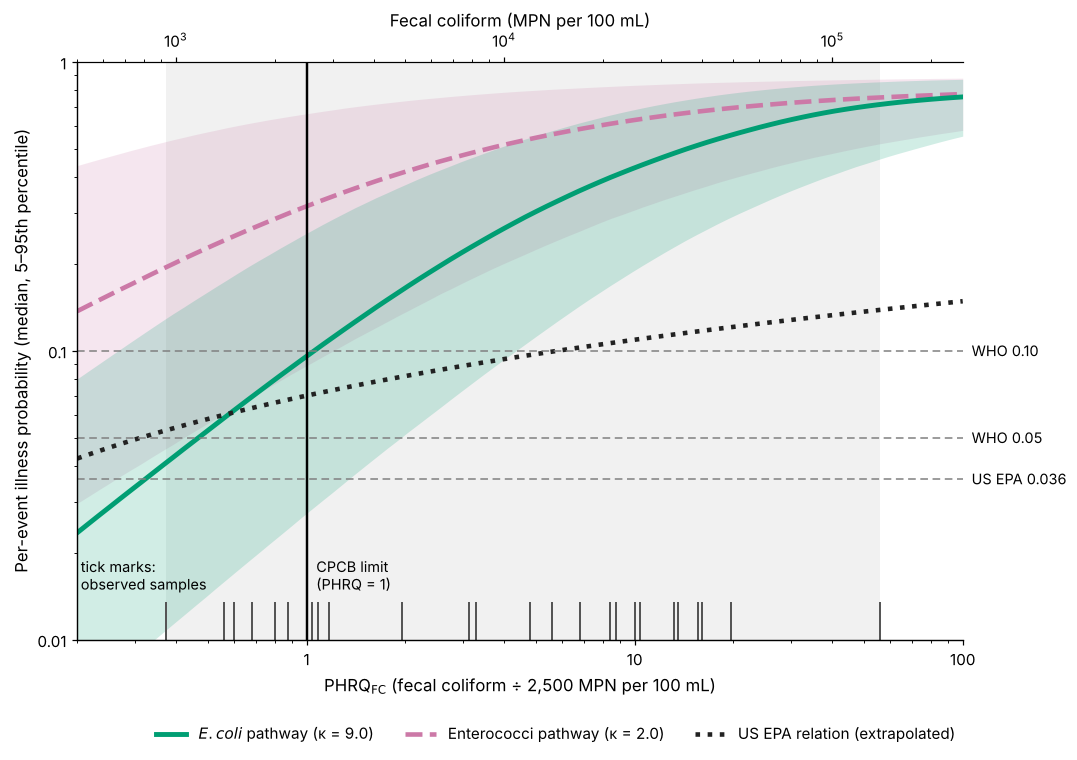

In [27]:
# ---- Fig. 6: per-event illness versus PHRQ_FC ---------------------------------------------
fig, ax = plt.subplots(figsize=(10.2, 6.8))
ax.axvspan(df.phrq_fc.min(), df.phrq_fc.max(), color="#f1f1f1", lw=0, zorder=0)
ax.fill_between(PHRQ_GRID, curve["ent"][:, 1], curve["ent"][:, 2], color=COL["pink"], alpha=0.18, lw=0)
ax.fill_between(PHRQ_GRID, curve["ecoli"][:, 1], curve["ecoli"][:, 2], color=COL["green"], alpha=0.18, lw=0)
ax.plot(PHRQ_GRID, curve["ent"][:, 0], color=COL["pink"], ls="--", lw=3)
ax.plot(PHRQ_GRID, curve["ecoli"][:, 0], color=COL["green"], lw=3.2)
ax.plot(PHRQ_GRID, epa_curve, color=COL["ink"], ls=":", lw=3)
for y, lab in [(0.10, "WHO 0.10"), (0.05, "WHO 0.05"), (0.036, "US EPA 0.036")]:
    ax.axhline(y, color="gray", ls=(0, (5, 3)), lw=1); ax.text(1.01, y, lab, transform=ax.get_yaxis_transform(), va="center", fontsize=9.5)
ax.axvline(1, color="k", lw=1.6)
ax.vlines(df.phrq_fc, 0.01, 0.0135, color="#555555", lw=1.3)
ax.text(0.205, 0.0145, "tick marks:\nobserved samples", fontsize=9.5, va="bottom")
ax.text(1.07, 0.0145, "CPCB limit\n(PHRQ = 1)", fontsize=9.5, va="bottom")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.2, 100); ax.set_ylim(0.01, 1)
plain_ticks(ax, "x", [1, 10, 100]); plain_ticks(ax, "y", [0.01, 0.1, 1])
ax.set_xlabel("PHRQ$_{\\mathrm{FC}}$ (fecal coliform ÷ 2,500 MPN per 100 mL)", fontsize=11)
ax.set_ylabel("Per-event illness probability (median, 5–95th percentile)", fontsize=11)
top = ax.twiny(); top.set_xscale("log"); top.set_xlim(0.2 * FC_LIMIT, 100 * FC_LIMIT)
top.set_xlabel("Fecal coliform (MPN per 100 mL)", fontsize=11); top.spines["top"].set_visible(True)
fig.legend(handles=[Line2D([], [], color=COL["green"], lw=3.2, label="$E. coli$ pathway (κ = 9.0)"),
                    Line2D([], [], color=COL["pink"], lw=3, ls="--", label="Enterococci pathway (κ = 2.0)"),
                    Line2D([], [], color=COL["ink"], lw=3, ls=":", label="US EPA relation (extrapolated)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02), fontsize=10)
fig.tight_layout(rect=(0, 0.04, 0.97, 1))
save_fig(fig, "Fig6_illness_vs_PHRQ")

In [28]:
# ---- Table S5 (A): illness at PHRQ_FC = 0.2, 1, 10, 100, with pathogen detail -------------------
REP_MAP = {0.2: {"ecoli": (0.0236, 0.00600, 0.0805), "ent": (0.138, 0.0293, 0.441)},
           1.0: {"ecoli": (0.0961, 0.0275, 0.255), "ent": (0.318, 0.0878, 0.664)},
           10.0: {"ecoli": (0.432, 0.192, 0.683), "ent": (0.630, 0.308, 0.829)},
           100.0: {"ecoli": (0.756, 0.555, 0.870), "ent": (0.774, 0.582, 0.878)}}
rows = []
for ph in (0.2, 1.0, 10.0, 100.0):
    for pw in ("ecoli", "ent"):
        ind = predicted_indicator(ph, pw, rn_map)
        comb, per, _ = combined_illness(ind, pw, VOL_BASE, rn_map); m = summ(comb)
        rows.append({"PHRQ_FC": ph, "FC per 100 mL": ph * FC_LIMIT, "Pathway": LABEL[pw].replace(" pathway", ""),
                     "Predicted indicator (median)": float(np.median(ind)), "Illness median": m[0], "5th": m[1], "95th": m[2],
                     **{NAMES[p]: float(np.median(per[p])) for p in ["noro", "adeno", "giar", "camp"]},
                     "US EPA relation": epa_relation(np.median(ind)) if pw == "ecoli" else np.nan,
                     "Paper median": REP_MAP[ph][pw][0]})
table_s5a = pd.DataFrame(rows).set_index(["PHRQ_FC", "Pathway"])
display(table_s5a.round(4)); save_table(table_s5a.round(5), "Table_S5A_illness_vs_PHRQ")
worst_s5a = max(abs(r["Illness median"] / r["Paper median"] - 1) for r in rows)

# PHRQ at which the median illness reaches each benchmark
BENCH = [0.032, 0.036, 0.05, 0.10]
cross = {}
for pw in ("ecoli", "ent"):
    f = lambda lp, b: float(np.median(combined_illness(predicted_indicator(10 ** lp, pw, rn_map), pw, VOL_BASE, rn_map)[0])) - b
    cross[pw] = ["≤ 0.2" if f(np.log10(0.2), b) >= 0 else f"{10 ** brentq(f, np.log10(0.2), np.log10(100), args=(b,), xtol=1e-4):.2f}" for b in BENCH]
cross_tbl = pd.DataFrame(cross, index=[f"illness {b}" for b in BENCH]).rename(columns=LABEL).T
display(cross_tbl); save_table(cross_tbl, "Table_S5_PHRQ_at_benchmarks")
print("Paper: E. coli pathway 0.28, 0.32, 0.46, 1.05; enterococci pathway already above all four benchmarks at PHRQ_FC = 0.2.")

FC per 100 mL  Predicted indicator (median)  \
PHRQ_FC Pathway                                                    
0.2     E. coli              500.0                      178.4452   
        Enterococci          500.0                      295.0128   
1.0     E. coli             2500.0                      800.7145   
        Enterococci         2500.0                      878.4346   
10.0    E. coli            25000.0                     6791.6508   
        Enterococci        25000.0                     4191.2881   
100.0   E. coli           250000.0                    57569.9813   
        Enterococci       250000.0                    20008.0887   

                     Illness median     5th    95th  Norovirus GI  Adenovirus  \
PHRQ_FC Pathway                                                                 
0.2     E. coli              0.0235  0.0059  0.0800        0.0124      0.0047   
        Enterococci          0.1371  0.0296  0.4378        0.0513      0.0205   
1.0     E. coli              0.0957  0.0274  0.2551        0.0504      0.0207   
        Enterococci          0.3165  0.0888  0.6618        0.1200      0.0587   
10.0    E. coli              0.4302  0.1900  0.6841        0.1910      0.1517   
        Enterococci          0.6296  0.3072  0.8299        0.2209      0.2251   
100.0   E. coli              0.7567  0.5535  0.8706        0.2652      0.4765   
        Enterococci          0.7738  0.5796  0.8788        0.2665      0.4708   

                     Giardia lamblia  Campylobacter  US EPA relation  \
PHRQ_FC Pathway                                                        
0.2     E. coli               0.0044         0.0000           0.0424   
        Enterococci           0.0585         0.0003              NaN   
1.0     E. coli               0.0194         0.0001           0.0699   
        Enterococci           0.1503         0.0008              NaN   
10.0    E. coli               0.1374         0.0008           0.1092   
        Enterococci           0.3360         0.0038              NaN   
100.0   E. coli               0.3867         0.0061           0.1485   
        Enterococci           0.4260         0.0153              NaN   

                     Paper median  
PHRQ_FC Pathway                    
0.2     E. coli            0.0236  
        Enterococci        0.1380  
1.0     E. coli            0.0961  
        Enterococci        0.3180  
10.0    E. coli            0.4320  
        Enterococci        0.6300  
100.0   E. coli            0.7560  
        Enterococci        0.7740

,illness 0.032,illness 0.036,illness 0.05,illness 0.1
E. coli pathway,0.28,0.32,0.47,1.05
Enterococci pathway,≤ 0.2,≤ 0.2,≤ 0.2,≤ 0.2


Paper: E. coli pathway 0.28, 0.32, 0.46, 1.05; enterococci pathway already above all four benchmarks at PHRQ_FC = 0.2.


## 10 · Sensitivity analysis

### 10a · Alternative inputs at PHRQ_FC = 1 (Table S5 B)
Each input is changed *one at a time* while the others stay at their primary values (κ held at its calibrated value), to see which assumptions the result at the CPCB limit depends on:
**ingestion** (heavier scenario 35–100–200 mL), **illness given infection** set at the lower or upper bound of its range, and **pathogen:indicator ratios** fixed at their minimum or maximum.

In [29]:
REP_SCEN = {"heavy": {"ecoli": (0.259, 0.0877, 0.515), "ent": (0.577, 0.243, 0.812)},
            "ill_low": {"ecoli": (0.0620, 0.0184, 0.162), "ent": (0.196, 0.0551, 0.431)},
            "ill_high": {"ecoli": (0.134, 0.0394, 0.330), "ent": (0.443, 0.130, 0.802)},
            "ratio_min": {"ecoli": (0.00900, 0.00300, 0.0255), "ent": (0.0645, 0.0163, 0.207)},
            "ratio_max": {"ecoli": (0.178, 0.0672, 0.373), "ent": (0.484, 0.183, 0.760)}}
SCEN_LABEL = {"heavy": "Heavier ingestion (35, 100, 200 mL)", "ill_low": "Illness given infection at lower bounds",
              "ill_high": "Illness given infection at upper bounds", "ratio_min": "Pathogen:indicator ratios at minimum",
              "ratio_max": "Pathogen:indicator ratios at maximum"}
rows = []; scen_num = {}
for scen in ("heavy", "ill_low", "ill_high", "ratio_min", "ratio_max"):
    vol = VOL_HEAVY if scen == "heavy" else VOL_BASE
    row = {"Scenario": SCEN_LABEL[scen]}
    for pw in ("ecoli", "ent"):
        comb, _, _ = combined_illness(predicted_indicator(1.0, pw, rn_map), pw, vol, rn_map, scen=scen)
        m = summ(comb); rep = REP_SCEN[scen][pw]; scen_num[(scen, pw)] = m[0]
        row[f"{LABEL[pw]}: median (5th–95th)"] = f"{m[0]:.4f} ({m[1]:.4f}–{m[2]:.3f})"
        row[f"paper median ({pw})"] = rep[0]
    rows.append(row)
scen_tbl = pd.DataFrame(rows).set_index("Scenario")
display(scen_tbl); save_table(scen_tbl, "Table_S5B_sensitivity_scenarios")
print("Baseline at PHRQ_FC = 1: E. coli pathway 0.0961, enterococci pathway 0.318 (Step 9).")

,E. coli pathway: median (5th–95th),paper median (ecoli),Enterococci pathway: median (5th–95th),paper median (ent)
Scenario,,,,
"Heavier ingestion (35, 100, 200 mL)",0.2582 (0.0874–0.515),0.259,0.5759 (0.2437–0.812),0.5770
Illness given infection at lower bounds,0.0613 (0.0180–0.162),0.062,0.1943 (0.0551–0.431),0.1960
Illness given infection at upper bounds,0.1326 (0.0391–0.331),0.134,0.4411 (0.1299–0.801),0.4430
Pathogen:indicator ratios at minimum,0.0089 (0.0029–0.026),0.009,0.0639 (0.0161–0.210),0.0645
Pathogen:indicator ratios at maximum,0.1768 (0.0664–0.374),0.178,0.4810 (0.1812–0.762),0.4840


Baseline at PHRQ_FC = 1: E. coli pathway 0.0961, enterococci pathway 0.318 (Step 9).


### 10b · Which inputs matter most? Rank correlations (extra table, extra figure E4)
Spearman rank correlations between the combined illness probability and each random input, across the Monte Carlo draws at PHRQ_FC = 1. A large |ρ| means that input drives the spread of the result. The indicator concentration (itself a function of the FC regression and its scatter) dominates; ingestion and the norovirus ratio come next.

,"E. coli pathway, PHRQ 1","Enterococci pathway, PHRQ 1","E. coli pathway, PHRQ 10","Enterococci pathway, PHRQ 10"
Indicator concentration,0.719,0.800,0.675,0.684
Ingestion,0.355,0.284,0.353,0.254
"Ratio, Campylobacter",-0.001,-0.004,-0.003,0.000
"Ratio, Adenovirus",0.191,0.119,0.326,0.227
"Ratio, Norovirus GI",0.414,0.157,0.219,0.077
"Ratio, Giardia",0.159,0.319,0.265,0.277
"Illness|infection, Campylobacter",-0.003,0.002,-0.001,0.005
"Illness|infection, Norovirus GI",0.203,0.138,0.232,0.177
"Illness|infection, Giardia",0.115,0.235,0.219,0.437


Paper (PHRQ 1): indicator 0.72 / 0.80, ingestion 0.35 / 0.28, norovirus ratio 0.41 / 0.15 (E. coli / enterococci pathway).


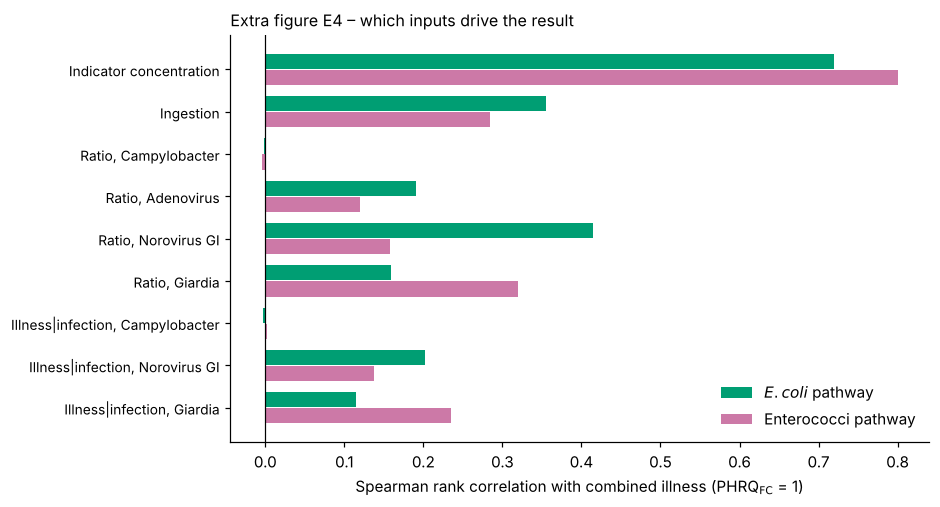

In [30]:
def spearman_table(phrq, pw, rn=rn_map):
    ind = predicted_indicator(phrq, pw, rn); comb, _, _ = combined_illness(ind, pw, VOL_BASE, rn)
    inputs = {"Indicator concentration": ind, "Ingestion": rn.u_vol,
              "Ratio, Campylobacter": rn.u_ratio["camp"], "Ratio, Adenovirus": rn.u_ratio["adeno"],
              "Ratio, Norovirus GI": rn.u_ratio["noro"], "Ratio, Giardia": rn.u_ratio["giar"],
              "Illness|infection, Campylobacter": rn.u_ill["camp"], "Illness|infection, Norovirus GI": rn.u_ill["noro"],
              "Illness|infection, Giardia": rn.u_ill["giar"]}
    return {k: stats.spearmanr(v, comb)[0] for k, v in inputs.items()}
sp = pd.DataFrame({f"{LABEL[pw]}, PHRQ 1": spearman_table(1.0, pw) for pw in ("ecoli", "ent")})
sp.update(pd.DataFrame({f"{LABEL[pw]}, PHRQ 10": spearman_table(10.0, pw) for pw in ("ecoli", "ent")}))
sp = pd.concat([pd.DataFrame({f"{LABEL[pw]}, PHRQ 1": spearman_table(1.0, pw) for pw in ("ecoli", "ent")}),
                pd.DataFrame({f"{LABEL[pw]}, PHRQ 10": spearman_table(10.0, pw) for pw in ("ecoli", "ent")})], axis=1)
display(sp.round(3)); save_table(sp.round(4), "Extra_rank_correlations")
print("Paper (PHRQ 1): indicator 0.72 / 0.80, ingestion 0.35 / 0.28, norovirus ratio 0.41 / 0.15 (E. coli / enterococci pathway).")

fig, ax = plt.subplots(figsize=(8.2, 4.8)); y = np.arange(len(sp))[::-1]
ax.barh(y + 0.19, sp.iloc[:, 0], height=0.36, color=COL["green"], label="$E. coli$ pathway")
ax.barh(y - 0.19, sp.iloc[:, 1], height=0.36, color=COL["pink"], label="Enterococci pathway")
ax.set_yticks(y); ax.set_yticklabels(sp.index, fontsize=9); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Spearman rank correlation with combined illness (PHRQ$_{\\mathrm{FC}}$ = 1)"); ax.legend(loc="lower right")
ax.set_title("Extra figure E4 – which inputs drive the result", loc="left", fontsize=10.5)
save_fig(fig, "FigE4_rank_correlations")

### 10c · The ingestion-volume check: does the volume matter once κ is recalibrated?
The baseline ingestion distribution (10–35–50 mL) is a central-tendency swimmer value, and the heavier scenario (35–100–200 mL) is an assumption. Because **κ is calibrated to the US EPA criterion with a given ingestion distribution**, changing the ingestion distribution changes the level of every result *unless κ is recalibrated*. The table separates the two effects: (i) the heavier ingestion with the **same κ** (what Table S5 B reports: risk goes up), and (ii) the heavier ingestion with **κ re-solved** for it (the calibration absorbs most of the change). Edit `VOL_CUSTOM` to test your own range.

In [31]:
VOL_CUSTOM = (20.0, 40.0, 80.0)        # <- edit: your own triangular (min, mode, max) in mL
rn_chk = Draws(400_000, SEED + 41)

def ingestion_check(vol, label):
    row = {"Ingestion (mL)": f"{vol[0]:g}–{vol[1]:g}–{vol[2]:g}", "Case": label}
    k_new = {pw: brentq(lambda k: expected_illness(pw, k, vol=vol, rn=rn_chk) - EPA_TARGET, 0.05, 100, xtol=1e-3) for pw in ("ecoli", "ent")}
    for pw in ("ecoli", "ent"):
        row[f"median at PHRQ 1, κ fixed ({pw})"] = median_at(1.0, pw, KAPPA[pw], rn=rn_chk, vol=vol)
    row["recalibrated κ (E. coli, enterococci)"] = f"{k_new['ecoli']:.2f}, {k_new['ent']:.2f}"
    for pw in ("ecoli", "ent"):
        row[f"median at PHRQ 1, κ recalibrated ({pw})"] = median_at(1.0, pw, k_new[pw], rn=rn_chk, vol=vol)
    return row
t0 = time.time()
ing = pd.DataFrame([ingestion_check(VOL_BASE, "baseline"), ingestion_check(VOL_HEAVY, "heavier scenario"),
                    ingestion_check(VOL_CUSTOM, "VOL_CUSTOM")]).set_index("Case")
display(ing.round(4)); save_table(ing.round(5), "Table_ingestion_check")
print(f"({time.time() - t0:.0f} s)  Reading: with κ fixed, heavier ingestion raises the median at the limit from ≈0.096 to ≈0.26;")
print("with κ recalibrated to the same US EPA anchor the median returns to ≈0.09–0.10, so the level at the CPCB limit is set by the EPA anchor, not by the volume.")

,Ingestion (mL),"median at PHRQ 1, κ fixed (ecoli)","median at PHRQ 1, κ fixed (ent)","recalibrated κ (E. coli, enterococci)","median at PHRQ 1, κ recalibrated (ecoli)","median at PHRQ 1, κ recalibrated (ent)"
Case,,,,,,
baseline,10–35–50,0.0958,0.3170,"8.87, 2.00",0.0945,0.3172
heavier scenario,35–100–200,0.2580,0.5758,"2.52, 0.57",0.0937,0.3152
VOL_CUSTOM,20–40–80,0.1335,0.3993,"6.02, 1.36",0.0942,0.3170


(6 s)  Reading: with κ fixed, heavier ingestion raises the median at the limit from ≈0.096 to ≈0.26;
with κ recalibrated to the same US EPA anchor the median returns to ≈0.09–0.10, so the level at the CPCB limit is set by the EPA anchor, not by the volume.


## 11 · Dose–response alternatives (subset of Table 2)
Does the result depend on the particular dose–response or illness model? Following Section 2.9, one component is replaced at a time and **κ is recalibrated to the same US EPA anchor**, so that any remaining difference comes from the *shape* of the model, not its level. Four of the paper's twelve alternatives (Table 2) need only the equations already in this notebook and are reproduced here next to the primary set; the other eight (the *Campylobacter* pair with its own illness model, the approximate beta-Poisson form, the disaggregated and aggregation-adjusted norovirus models, and the adenovirus and combined sets) need extra model code and are not reproduced.

In [32]:
def with_(**changes):
    spec = {p: dict(v) for p, v in PRIMARY.items()}
    for p, v in changes.items(): spec[p].update(v)
    return spec
ALTS = {
    "Primary set": PRIMARY,
    "Campylobacter: Teunis pair α = 0.024, β = 0.011": with_(camp=dict(infect=bp_infect(0.024, 0.011))),
    "Campylobacter: illness PERT(0.1, 0.28, 0.6)": with_(camp=dict(ill=("pert", 0.1, 0.28, 0.6))),
    "Norovirus: constant illness 0.6": with_(noro=dict(ill=("const", 0.6))),
    "Norovirus: dose-dependent illness 1−(1+ηD)^−r": with_(noro=dict(ill=("dosedep", 2.55e-3, 0.086))),
}
REP_D29 = {"Primary set": (0.0961, 0.3181, 9.013, 2.021, 0.0962, 0.3204, 0.4318, 0.6315, 0.32),
           "Campylobacter: Teunis pair α = 0.024, β = 0.011": (0.0999, 0.3448, 8.635, 1.861, 0.0963, 0.329, 0.4418, 0.6645, 0.32),
           "Campylobacter: illness PERT(0.1, 0.28, 0.6)": (0.0962, 0.318, 9.055, 2.032, 0.0968, 0.3213, 0.4328, 0.6319, 0.32),
           "Norovirus: constant illness 0.6": (0.1024, 0.3287, 8.529, 1.95, 0.0976, 0.3235, 0.4327, 0.6357, 0.32),
           "Norovirus: dose-dependent illness 1−(1+ηD)^−r": (0.0431, 0.2127, 20.842, 3.367, 0.0952, 0.3078, 0.473, 0.5984, 0.33)}
rn_alt = Draws(400_000, SEED + 51)
rows = []; t0 = time.time()
for name, spec in ALTS.items():
    k = {pw: brentq(lambda x: expected_illness(pw, x, rn=rn_alt, spec=spec) - EPA_TARGET, 0.05, 150, xtol=1e-3) for pw in ("ecoli", "ent")}
    cross = 10 ** brentq(lambda lp: median_at(10 ** lp, "ecoli", k["ecoli"], rn=rn_alt, spec=spec) - 0.036, np.log10(0.05), np.log10(20), xtol=1e-3)
    rows.append({"Alternative": name,
                 "κ fixed: median PHRQ 1 (E. coli / ent)": f"{median_at(1.0, 'ecoli', KAPPA['ecoli'], rn=rn_alt, spec=spec):.4f} / {median_at(1.0, 'ent', KAPPA['ent'], rn=rn_alt, spec=spec):.4f}",
                 "recalibrated κ": f"{k['ecoli']:.2f} / {k['ent']:.2f}",
                 "recalibrated: median PHRQ 1": f"{median_at(1.0, 'ecoli', k['ecoli'], rn=rn_alt, spec=spec):.4f} / {median_at(1.0, 'ent', k['ent'], rn=rn_alt, spec=spec):.4f}",
                 "recalibrated: median PHRQ 10": f"{median_at(10.0, 'ecoli', k['ecoli'], rn=rn_alt, spec=spec):.4f} / {median_at(10.0, 'ent', k['ent'], rn=rn_alt, spec=spec):.4f}",
                 "PHRQ reaching 0.036": f"{cross:.2f}",
                 "paper: κ fixed / recalibrated κ / PHRQ 1": f"{REP_D29[name][0]} / {REP_D29[name][1]};  {REP_D29[name][2]} / {REP_D29[name][3]};  {REP_D29[name][4]} / {REP_D29[name][5]}"})
alt_tbl = pd.DataFrame(rows).set_index("Alternative")
display(alt_tbl); save_table(alt_tbl, "Table2_dose_response_alternatives_subset")
print(f"({time.time() - t0:.0f} s)  After recalibration the median at the CPCB limit (PHRQ 1) stays close to 0.095 (E. coli) and 0.31–0.33 (enterococci) for every alternative.")

,κ fixed: median PHRQ 1 (E. coli / ent),recalibrated κ,recalibrated: median PHRQ 1,recalibrated: median PHRQ 10,PHRQ reaching 0.036,paper: κ fixed / recalibrated κ / PHRQ 1
Alternative,,,,,,
Primary set,0.0955 / 0.3170,8.90 / 2.00,0.0945 / 0.3174,0.4280 / 0.6300,0.33,0.0961 / 0.3181; 9.013 / 2.021; 0.0962 / 0.3204
"Campylobacter: Teunis pair α = 0.024, β = 0.011",0.0994 / 0.3429,8.53 / 1.85,0.0947 / 0.3253,0.4379 / 0.6624,0.33,0.0999 / 0.3448; 8.635 / 1.861; 0.0963 / 0.329
"Campylobacter: illness PERT(0.1, 0.28, 0.6)",0.0955 / 0.3168,8.90 / 2.01,0.0945 / 0.3174,0.4279 / 0.6298,0.33,0.0962 / 0.318; 9.055 / 2.032; 0.0968 / 0.3213
Norovirus: constant illness 0.6,0.1014 / 0.3273,8.42 / 1.93,0.0956 / 0.3201,0.4295 / 0.6337,0.32,0.1024 / 0.3287; 8.529 / 1.95; 0.0976 / 0.3235
Norovirus: dose-dependent illness 1−(1+ηD)^−r,0.0429 / 0.2123,20.48 / 3.33,0.0933 / 0.3047,0.4683 / 0.5969,0.34,0.0431 / 0.2127; 20.842 / 3.367; 0.0952 / 0....


(34 s)  After recalibration the median at the CPCB limit (PHRQ 1) stays close to 0.095 (E. coli) and 0.31–0.33 (enterococci) for every alternative.


## 12 · Statistics quoted in the text, and annual risk

These calculations need only the dataset (and, for annual risk, the model of Steps 5–8). They reproduce numbers quoted in Sections 2.3, 3.1–3.4 and 3.7 of the paper:

* **12a** descriptive statistics (Spearman correlations, indicator ratios, PHRQ by site and season), exceedance of the CPCB limits with Wilson 95 % intervals, and compliance of the monthly geometric mean;
* **12b** linear mixed models of log₁₀ concentration (site and season as fixed effects, random intercept for the sampling occasion), likelihood-ratio tests, intraclass correlations, and the Friedman, Kruskal–Wallis and Mann–Whitney tests;
* **12c** annual illness probability for 1, 12 and 52 events per year (two-dimensional Monte Carlo: ratios and illness given infection drawn once per iteration, concentration and volume per event).

In [33]:
# ---- 12a · descriptive statistics quoted in the text; exceedance with Wilson intervals; monthly compliance ----
rho_ec = stats.spearmanr(df.fecal_coliform, df.e_coli)[0]
rho_ent = stats.spearmanr(df.fecal_streptococci, df.enterococci)[0]
ratios = pd.DataFrame({"E. coli : FC": df.e_coli / df.fecal_coliform, "Enterococci : FS": df.enterococci / df.fecal_streptococci,
                       "FC / FS": df.fc_fs_ratio})
ratio_summary = ratios.describe(percentiles=[0.25, 0.5, 0.75]).loc[["min", "25%", "50%", "75%", "max"]].T
ratio_summary.columns = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
save_table(ratio_summary, "Extra_indicator_ratios"); display(ratio_summary.round(3))
print(f"Spearman rho (n = 44): FC vs E. coli {rho_ec:.2f}; FS vs enterococci {rho_ent:.2f}")
phrq_ss = (df.groupby(["site_code", "season"]).agg(PHRQ_FC_median=("phrq_fc", "median"), PHRQ_FS_median=("phrq_fs", "median"),
                                                  n=("phrq_fc", "size")).reset_index())
phrq_ss.insert(1, "Site", phrq_ss.site_code.map(SITE))
save_table(phrq_ss, "Extra_PHRQ_by_site_season", index=False); display(phrq_ss.round(2))
print("Checks against Sections 3.2 and 3.4 of the paper:")
for _args in [("Spearman rho, FC vs E. coli", rho_ec, 0.85, 0.02), ("Spearman rho, FS vs enterococci", rho_ent, 0.83, 0.02),
              ("median E. coli : FC ratio", ratio_summary.loc["E. coli : FC", "Median"], 0.27, 0.03),
              ("median enterococci : FS ratio", ratio_summary.loc["Enterococci : FS", "Median"], 0.31, 0.03),
              ("lowest site-season median PHRQ_FC (all 12 exceed 1)", phrq_ss.PHRQ_FC_median.min(), 1.2, 0.05),
              ("lowest site-season median PHRQ_FS", phrq_ss.PHRQ_FS_median.min(), 6.6, 0.05)]:
    check(*_args)

# ---- exceedance with Wilson intervals; compliance of the monthly geometric mean ----------------------------------
from statsmodels.stats.proportion import proportion_confint
groups = [("All samples", df)] + [(name, df[df.site_code == s]) for s, name in SITE.items()] + [(se, df[df.season == se]) for se in SEASONS]
rows = []
for g, sub in groups:
    for metric, col_, lim in (("FC", "fecal_coliform", FC_LIMIT), ("FS", "fecal_streptococci", FS_LIMIT)):
        k, n = int((sub[col_] > lim).sum()), len(sub)
        lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
        rows.append({"Group": g, "n": n, "Indicator": metric, "Samples above limit": k, "Proportion": k / n,
                     "Wilson 95% low": lo, "Wilson 95% high": hi})
exceed = save_table(pd.DataFrame(rows), "Extra_exceedance_wilson", index=False)
display(exceed.round(3))

_gm = lambda x: float(np.exp(np.log(x).mean()))
monthly = df.groupby("date").agg(FC_GM=("fecal_coliform", _gm), FS_GM=("fecal_streptococci", _gm))
monthly["FC within limit"] = np.where(monthly.FC_GM <= FC_LIMIT, "yes", "no")
monthly["FS within limit"] = np.where(monthly.FS_GM <= FS_LIMIT, "yes", "no")
save_table(monthly, "Extra_monthly_compliance")
display(monthly.round(0))
n_fc_ok = int((monthly["FC within limit"] == "yes").sum()); n_fs_ok = int((monthly["FS within limit"] == "yes").sum())
print(f"Sampling occasions with the FC geometric mean within the limit: {n_fc_ok} of {len(monthly)}; FS: {n_fs_ok} of {len(monthly)}")

,Minimum,Q1,Median,Q3,Maximum
E. coli : FC,0.069,0.233,0.274,0.398,0.900
Enterococci : FS,0.050,0.180,0.308,0.490,1.000
FC / FS,0.182,0.969,1.300,2.413,14.848


Spearman rho (n = 44): FC vs E. coli 0.85; FS vs enterococci 0.83


,site_code,Site,season,PHRQ_FC_median,PHRQ_FS_median,n
0,A,U/S Assi Ghat,Dry,10.00,6.6,5
1,A,U/S Assi Ghat,Monsoon,10.20,25.0,4
2,A,U/S Assi Ghat,Post-monsoon,7.20,17.0,2
3,B,Assi Ghat,Dry,15.60,22.0,5
4,B,Assi Ghat,Monsoon,13.00,190.0,4
5,B,Assi Ghat,Post-monsoon,4.96,19.1,2
6,C,Dashashwamedh Ghat,Dry,1.96,22.0,5
7,C,Dashashwamedh Ghat,Monsoon,11.00,54.0,4
8,C,Dashashwamedh Ghat,Post-monsoon,3.20,11.2,2
9,D,Kardameshwar Pond,Dry,1.17,9.6,5


Checks against Sections 3.2 and 3.4 of the paper:
  ✓ Spearman rho, FC vs E. coli: notebook 0.8494  |  paper 0.85
  ✓ Spearman rho, FS vs enterococci: notebook 0.8348  |  paper 0.83
  ✓ median E. coli : FC ratio: notebook 0.2735  |  paper 0.27
  ✓ median enterococci : FS ratio: notebook 0.3084  |  paper 0.31
  ✓ lowest site-season median PHRQ_FC (all 12 exceed 1): notebook 1.173  |  paper 1.2
  ✓ lowest site-season median PHRQ_FS: notebook 6.6  |  paper 6.6


,Group,n,Indicator,Samples above limit,Proportion,Wilson 95% low,Wilson 95% high
0,All samples,44,FC,36,0.818,0.680,0.905
1,All samples,44,FS,42,0.955,0.849,0.987
2,U/S Assi Ghat,11,FC,9,0.818,0.523,0.949
3,U/S Assi Ghat,11,FS,11,1.000,0.741,1.000
4,Assi Ghat,11,FC,9,0.818,0.523,0.949
5,Assi Ghat,11,FS,10,0.909,0.623,0.984
6,Dashashwamedh Ghat,11,FC,9,0.818,0.523,0.949
7,Dashashwamedh Ghat,11,FS,11,1.000,0.741,1.000
8,Kardameshwar Pond,11,FC,9,0.818,0.523,0.949
9,Kardameshwar Pond,11,FS,10,0.909,0.623,0.984


,FC_GM,FS_GM,FC within limit,FS within limit
date,,,,
2025-06-17,30965.0,39743.0,no,no
2025-07-15,25907.0,17045.0,no,no
2025-08-19,19606.0,8137.0,no,no
2025-09-23,18986.0,21883.0,no,no
2025-10-20,14141.0,9725.0,no,no
2025-11-26,5119.0,4578.0,no,no
2025-12-25,30965.0,12360.0,no,no
2026-01-20,25907.0,20696.0,no,no
2026-02-13,1501.0,2756.0,yes,no


Sampling occasions with the FC geometric mean within the limit: 2 of 11; FS: 0 of 11


In [34]:
# ---- 12b · mixed models, likelihood-ratio tests, intraclass correlation, rank tests ----------------------------
import statsmodels.formula.api as smf

def fit_lmm(formula, data, reml):
    """random-intercept model (one intercept per sampling occasion), fitted with the first optimiser that converges"""
    last = None
    for method in ("lbfgs", "bfgs", "powell", "nm"):
        try:
            with warnings.catch_warnings():       # statsmodels announces boundary / singular-matrix notices while the first
                warnings.simplefilter("ignore")   # optimiser is tried on a near-singular variance; the fallback converges
                return smf.mixedlm(formula, data, groups=data["occasion"]).fit(reml=reml, method=method)
        except Exception as err:
            last = err
    raise last

mm = df.copy()
mm["occasion"] = mm["date"].dt.strftime("%Y-%m-%d")
mm["site_c"] = pd.Categorical(mm["site_code"], categories=list("ABCD"))                       # reference: Site A
mm["season_c"] = pd.Categorical(mm["season"], categories=["Dry", "Monsoon", "Post-monsoon"])  # reference: dry season
INDICATORS = [("Fecal coliform", "fecal_coliform"), ("Fecal streptococci", "fecal_streptococci"),
              ("E. coli", "e_coli"), ("Enterococci", "enterococci")]
CONTRASTS = [("Site B vs Site A", "C(site_c)[T.B]"), ("Site C vs Site A", "C(site_c)[T.C]"), ("Site D vs Site A", "C(site_c)[T.D]"),
             ("Monsoon vs Dry", "C(season_c)[T.Monsoon]"), ("Post-monsoon vs Dry", "C(season_c)[T.Post-monsoon]")]
effects_rows, test_rows = [], []
for label, col_ in INDICATORS:
    mm["y"] = np.log10(mm[col_])
    full = fit_lmm("y ~ C(site_c) + C(season_c)", mm, reml=True)                  # fold-differences and Wald 95% intervals (REML)
    for name, key in CONTRASTS:
        b, se = full.params[key], full.bse[key]
        effects_rows.append({"Indicator": label, "Contrast": name, "Fold-difference": 10 ** b,
                             "95% CI low": 10 ** (b - 1.96 * se), "95% CI high": 10 ** (b + 1.96 * se), "p": full.pvalues[key]})
    v_occ, v_res = float(full.cov_re.iloc[0, 0]), float(full.scale)
    null = fit_lmm("y ~ 1", mm, reml=True); v0, r0 = float(null.cov_re.iloc[0, 0]), float(null.scale)
    ml_full = fit_lmm("y ~ C(site_c) + C(season_c)", mm, reml=False)              # likelihood-ratio tests (ML)
    ml_no_season = fit_lmm("y ~ C(site_c)", mm, reml=False)
    ml_no_site = fit_lmm("y ~ C(season_c)", mm, reml=False)
    wide = mm.pivot(index="occasion", columns="site_code", values=col_)
    test_rows.append({
        "Indicator": label, "Occasion variance": v_occ, "Residual variance": v_res, "ICC (site + season model)": v_occ / (v_occ + v_res),
        "ICC (null model)": v0 / (v0 + r0),
        "LRT season p": stats.chi2.sf(2 * (ml_full.llf - ml_no_season.llf), 2), "LRT site p": stats.chi2.sf(2 * (ml_full.llf - ml_no_site.llf), 3),
        "Friedman p (sites)": stats.friedmanchisquare(*[wide[s].values for s in "ABCD"]).pvalue,
        "Kruskal-Wallis p (season)": stats.kruskal(*[mm.loc[mm.season == s, col_] for s in SEASONS]).pvalue,
        "Mann-Whitney p (monsoon vs dry)": stats.mannwhitneyu(mm.loc[mm.season == "Monsoon", col_], mm.loc[mm.season == "Dry", col_], alternative="two-sided").pvalue})
effects = save_table(pd.DataFrame(effects_rows), "Extra_mixed_model_effects", index=False)
tests = save_table(pd.DataFrame(test_rows).set_index("Indicator"), "Extra_mixed_model_variance_and_tests")
display(effects.round(3)); display(tests.round(4))

print("Checks against the values quoted in Section 3.4 of the paper:")
_names = [x[0] for x in INDICATORS]
_checks = []
for label, p_paper in zip(_names, (0.15, 0.062, 0.27, 0.032)):
    _checks.append((f"monsoon-dry p, {label}", float(effects[(effects.Indicator == label) & (effects.Contrast == "Monsoon vs Dry")].p.iloc[0]), p_paper, 0.06))
for label, p_paper in zip(_names, (0.25, 0.13, 0.46, 0.079)):
    _checks.append((f"likelihood-ratio p for season, {label}", float(tests.loc[label, "LRT season p"]), p_paper, 0.06))
for label, p_paper in zip(_names, (0.035, 0.016, 0.12, 0.0030)):
    _checks.append((f"Kruskal-Wallis p for season, {label}", float(tests.loc[label, "Kruskal-Wallis p (season)"]), p_paper, 0.06))
_checks += [("smallest site likelihood-ratio p", float(tests["LRT site p"].min()), 0.0013, 0.06),
            ("largest site likelihood-ratio p", float(tests["LRT site p"].max()), 0.025, 0.06),
            ("smallest intraclass correlation", float(tests["ICC (site + season model)"].min()), 0.58, 0.02),
            ("largest intraclass correlation", float(tests["ICC (site + season model)"].max()), 0.83, 0.02)]
for _args in _checks:
    check(*_args)

,Indicator,Contrast,Fold-difference,95% CI low,95% CI high,p
0,Fecal coliform,Site B vs Site A,1.239,0.712,2.155,0.448
1,Fecal coliform,Site C vs Site A,0.694,0.399,1.207,0.195
2,Fecal coliform,Site D vs Site A,0.525,0.302,0.914,0.023
3,Fecal coliform,Monsoon vs Dry,2.846,0.677,11.959,0.153
4,Fecal coliform,Post-monsoon vs Dry,1.036,0.173,6.207,0.969
5,Fecal streptococci,Site B vs Site A,2.090,1.065,4.099,0.032
6,Fecal streptococci,Site C vs Site A,1.385,0.706,2.717,0.343
7,Fecal streptococci,Site D vs Site A,0.753,0.384,1.478,0.410
8,Fecal streptococci,Monsoon vs Dry,3.604,0.937,13.868,0.062
9,Fecal streptococci,Post-monsoon vs Dry,1.290,0.240,6.928,0.766


,Occasion variance,Residual variance,ICC (site + season model),ICC (null model),LRT season p,LRT site p,Friedman p (sites),Kruskal-Wallis p (season),Mann-Whitney p (monsoon vs dry)
Indicator,,,,,,,,,
Fecal coliform,0.2041,0.0828,0.7115,0.6671,0.2500,0.0165,0.0023,0.0351,0.1461
Fecal streptococci,0.1675,0.1225,0.5775,0.5671,0.1276,0.0254,0.1548,0.0162,0.0141
E. coli,0.2838,0.0588,0.8284,0.7837,0.4560,0.0240,0.0195,0.1161,0.1605
Enterococci,0.1567,0.0450,0.7770,0.7500,0.0786,0.0013,0.0204,0.0030,0.0018


Checks against the values quoted in Section 3.4 of the paper:
  ✓ monsoon-dry p, Fecal coliform: notebook 0.1532  |  paper 0.15
  ✓ monsoon-dry p, Fecal streptococci: notebook 0.06219  |  paper 0.062
  ✓ monsoon-dry p, E. coli: notebook 0.271  |  paper 0.27
  ✓ monsoon-dry p, Enterococci: notebook 0.03197  |  paper 0.032
  ✓ likelihood-ratio p for season, Fecal coliform: notebook 0.25  |  paper 0.25
  ✓ likelihood-ratio p for season, Fecal streptococci: notebook 0.1276  |  paper 0.13
  ✓ likelihood-ratio p for season, E. coli: notebook 0.456  |  paper 0.46
  ✓ likelihood-ratio p for season, Enterococci: notebook 0.07855  |  paper 0.079
  ✓ Kruskal-Wallis p for season, Fecal coliform: notebook 0.03508  |  paper 0.035
  ✓ Kruskal-Wallis p for season, Fecal streptococci: notebook 0.01618  |  paper 0.016
  ✓ Kruskal-Wallis p for season, E. coli: notebook 0.1161  |  paper 0.12
  ✓ Kruskal-Wallis p for season, Enterococci: notebook 0.003021  |  paper 0.003
  ✓ smallest site likelihood-ratio 

In [35]:
# ---- 12c · annual illness probability (1, 12 and 52 events per year), calibrated scaling -------------------------
def annual_risk(site_code, pathway, col_, n_iter, seed):
    """Two-dimensional Monte Carlo. Per iteration, the pathogen:indicator ratios and the illness-given-infection values are
    drawn once; for each of 52 events the indicator concentration (Gamma fit of the site) and the ingested volume are drawn.
    The annual probability after n events is 1 - prod(1 - per-event combined illness)."""
    rng = np.random.default_rng(seed)
    shape, _, scale = stats.gamma.fit(df.loc[df.site_code == site_code, col_].values / 1000.0, floc=0)
    ratio = {p: lo + (hi - lo) * rng.random((n_iter, 1)) for p, (lo, hi) in RATIO[pathway].items()}
    u_ill = {p: rng.random((n_iter, 1)) for p in PATHOGENS}
    conc = rng.gamma(shape, scale, (n_iter, 52)) * 1000.0
    vol = tri_ppf(rng.random((n_iter, 52)), *VOL_BASE)
    not_ill = []
    for p in PATHOGENS:
        dose = conc / 100.0 * ratio[p] * KAPPA[pathway] * vol
        not_ill.append(1.0 - PRIMARY[p]["infect"](dose) * illness_given_infection(PRIMARY[p]["ill"], u_ill[p], dose))
    event = 1.0 - np.prod(not_ill, axis=0)                       # combined per-event illness, shape (iterations, 52)
    after = lambda n: 1.0 - np.cumprod(1.0 - event, axis=1)[:, n - 1]
    a12 = after(12)
    return {"1 event (mean)": after(1).mean(), "12 events (mean)": a12.mean(), "52 events (mean)": after(52).mean(),
            "12 events (median)": np.median(a12), "12 events (5th percentile)": np.percentile(a12, 5),
            "12 events (95th percentile)": np.percentile(a12, 95)}

annual_rows, k = [], 0
for pathway, col_ in (("ecoli", "e_coli"), ("ent", "enterococci")):
    for s, name in SITE.items():
        annual_rows.append({"Pathway": LABEL[pathway], "Site": name, **annual_risk(s, pathway, col_, N_ANNUAL, SEED + 60 + k)}); k += 1
annual = save_table(pd.DataFrame(annual_rows), "Extra_annual_illness", index=False)
display(annual.round(4))
annual_min = float(annual["12 events (mean)"].min())
print(f"Lowest mean annual illness probability with 12 events per year: {annual_min:.3f} (the paper reports at least 0.97)")

,Pathway,Site,1 event (mean),12 events (mean),52 events (mean),12 events (median),12 events (5th percentile),12 events (95th percentile)
0,E. coli pathway,U/S Assi Ghat,0.3282,0.9836,1.0000,0.9950,0.9285,0.9999
1,E. coli pathway,Assi Ghat,0.4102,0.9951,1.0000,0.9992,0.9779,1.0000
2,E. coli pathway,Dashashwamedh Ghat,0.2964,0.9728,1.0000,0.9888,0.8913,0.9994
3,E. coli pathway,Kardameshwar Pond,0.2925,0.9703,0.9999,0.9871,0.8795,0.9992
4,Enterococci pathway,U/S Assi Ghat,0.5030,0.9987,1.0000,0.9999,0.9937,1.0000
5,Enterococci pathway,Assi Ghat,0.5639,0.9996,1.0000,1.0000,0.9984,1.0000
6,Enterococci pathway,Dashashwamedh Ghat,0.5693,0.9997,1.0000,1.0000,0.9985,1.0000
7,Enterococci pathway,Kardameshwar Pond,0.4551,0.9970,1.0000,0.9997,0.9854,1.0000


Lowest mean annual illness probability with 12 events per year: 0.970 (the paper reports at least 0.97)


## 13 · Figures that are not computed from the data

* **Fig. 1** (study-area map) combines GIS layers with third-party photographs and satellite imagery, so it is not redistributed here; see the article.
* **Fig. S1** (laboratory flowchart of the multiple-tube fermentation procedure) is an illustration in the Supplementary Information.
* The **analysis workflow diagram** is drawn below from code.

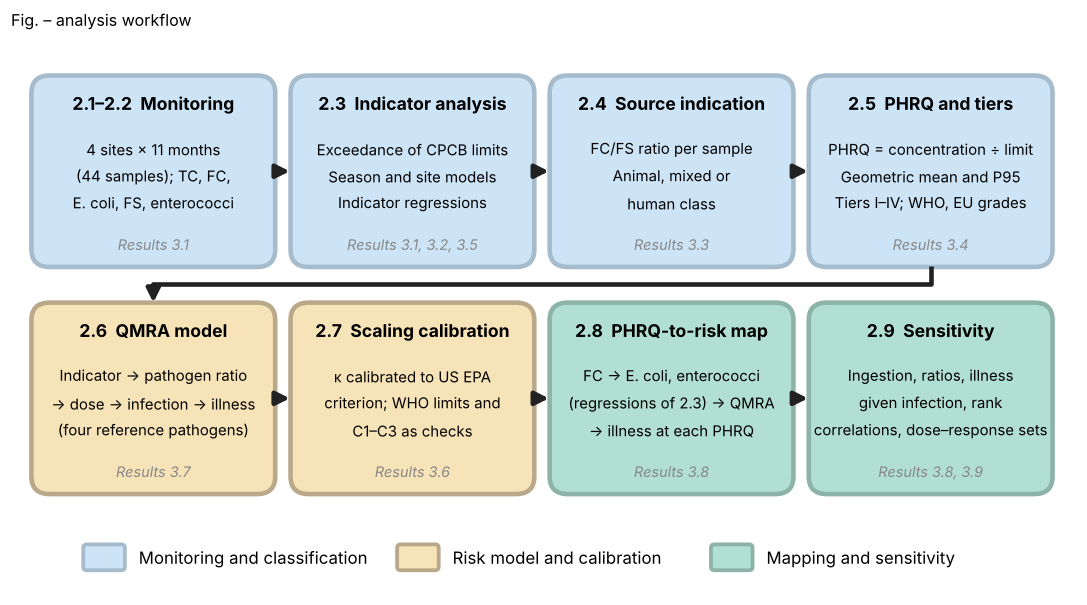

In [36]:
# ---- Fig.: analysis workflow------------------------------
fig, ax = plt.subplots(figsize=(12.5, 6.6)); ax.set_xlim(0, 14.6); ax.set_ylim(0, 8.0); ax.axis("off")
STY = {"blue": ("#CCE4F6", "#A6BBCB"), "beige": ("#F7E3B8", "#B9A98A"), "green": ("#B2DFD3", "#8DB3A8")}
boxes = [("blue", 0, "2.1–2.2  Monitoring", "4 sites × 11 months\n(44 samples); TC, FC,\nE. coli, FS, enterococci", "Results 3.1"),
         ("blue", 1, "2.3  Indicator analysis", "Exceedance of CPCB limits\nSeason and site models\nIndicator regressions", "Results 3.1, 3.2, 3.5"),
         ("blue", 2, "2.4  Source indication", "FC/FS ratio per sample\nAnimal, mixed or\nhuman class", "Results 3.3"),
         ("blue", 3, "2.5  PHRQ and tiers", "PHRQ = concentration ÷ limit\nGeometric mean and P95\nTiers I–IV; WHO, EU grades", "Results 3.4"),
         ("beige", 0, "2.6  QMRA model", "Indicator → pathogen ratio\n→ dose → infection → illness\n(four reference pathogens)", "Results 3.7"),
         ("beige", 1, "2.7  Scaling calibration", "κ calibrated to US EPA\ncriterion; WHO limits and\nC1–C3 as checks", "Results 3.6"),
         ("green", 2, "2.8  PHRQ-to-risk map", "FC → E. coli, enterococci\n(regressions of 2.3) → QMRA\n→ illness at each PHRQ", "Results 3.8"),
         ("green", 3, "2.9  Sensitivity", "Ingestion, ratios, illness\ngiven infection, rank\ncorrelations, dose–response sets", "Results 3.8, 3.9")]
W, H, xs = 3.3, 2.7, [0.3, 3.85, 7.4, 10.95]
for kind, i, title, body, res in boxes:
    top = kind == "blue"; y0 = 4.7 if top else 1.45; fc, ec = STY[kind]
    ax.add_patch(FancyBboxPatch((xs[i], y0), W, H, boxstyle="round,pad=0.02,rounding_size=0.25", fc=fc, ec=ec, lw=3))
    ax.text(xs[i] + W / 2, y0 + H - 0.38, title, ha="center", va="center", fontsize=11.5, fontweight="bold")
    ax.text(xs[i] + W / 2, y0 + H / 2 - 0.08, body, ha="center", va="center", fontsize=9.8, linespacing=1.5)
    ax.text(xs[i] + W / 2, y0 + 0.3, res, ha="center", va="center", fontsize=9.5, style="italic", color="#888888")
arrow = dict(arrowstyle="-|>", color="#222222", lw=3, mutation_scale=18, shrinkA=0, shrinkB=0)
for row_y in (6.05, 2.8):
    for i in range(3):
        if row_y == 2.8 and i == 0: ax.annotate("", (xs[1] - 0.03, row_y), (xs[0] + W + 0.03, row_y), arrowprops=arrow)
        elif row_y == 2.8 and i == 1: continue
        elif row_y == 2.8 and i == 2: ax.annotate("", (xs[3] - 0.03, row_y), (xs[2] + W + 0.03, row_y), arrowprops=arrow)
        else: ax.annotate("", (xs[i + 1] - 0.03, row_y), (xs[i] + W + 0.03, row_y), arrowprops=arrow)
ax.annotate("", (xs[2] - 0.03, 2.8), (xs[1] + W + 0.03, 2.8), arrowprops=arrow)
ax.plot([xs[3] + W / 2, xs[3] + W / 2, xs[0] + W / 2], [4.7, 4.43, 4.43], color="#222222", lw=3, solid_capstyle="butt")
ax.annotate("", (xs[0] + W / 2, 4.17), (xs[0] + W / 2, 4.43), arrowprops=arrow)
for k, (lab, kind) in enumerate([("Monitoring and classification", "blue"), ("Risk model and calibration", "beige"), ("Mapping and sensitivity", "green")]):
    x = 1.0 + k * 4.3; fc, ec = STY[kind]
    ax.add_patch(FancyBboxPatch((x, 0.35), 0.55, 0.35, boxstyle="round,pad=0.01,rounding_size=0.05", fc=fc, ec=ec, lw=2.5))
    ax.text(x + 0.75, 0.52, lab, va="center", fontsize=11)
ax.set_title("Fig. – analysis workflow", loc="left", fontsize=10.5)
save_fig(fig, "Fig_workflow")

## Reproducibility scoreboard

A one-glance comparison of the headline quantities with the values reported in the paper (tolerance: 3–5 % for the simulation-based quantities, which carry Monte Carlo noise; 2–6 % for the statistics of Step 12, which are compared at the precision printed in the paper).

In [37]:
board = []
def add(item, nb_val, paper_val, tol):
    board.append({"Quantity": item, "Notebook": round(float(nb_val), 4), "Paper": paper_val,
                  "Within tolerance": "✓" if abs(nb_val - paper_val) <= tol * abs(paper_val) else "⚠"})
add("Geometric mean fecal coliform, all samples (MPN/100 mL)", gmean(df.fecal_coliform), 12000, 0.03)
add("Geometric mean enterococci, all samples (MPN/100 mL)", gmean(df.enterococci), 2500, 0.03)
add("Samples above the FC limit (of 44)", int((df.fecal_coliform > FC_LIMIT).sum()), 36, 0.0)
add("Regression slope, E. coli on FC", REGR["E. coli ~ FC"]["b"], 0.929, 0.01)
add("PHRQ_FC geometric mean, Assi Ghat", PH[("FC", "B")]["gm"], 7.3, 0.02)
add("PHRQ_FS 95th percentile, Assi Ghat", PH[("FS", "B")]["p95"], 550, 0.02)
add("Gamma has the lowest AIC (series of 8)", int((fits["Lowest AIC"] == "Gamma").sum()), 4, 0.0)
add("kappa, E. coli pathway (unrounded)", kappa_solved["ecoli"], 8.97, 0.04)
add("kappa, enterococci pathway (unrounded)", kappa_solved["ent"], 2.01, 0.04)
add("Median illness at PHRQ_FC = 1, E. coli pathway", table_s5a.loc[(1.0, "E. coli"), "Illness median"], 0.0961, 0.04)
add("Median illness at PHRQ_FC = 1, enterococci pathway", table_s5a.loc[(1.0, "Enterococci"), "Illness median"], 0.318, 0.04)
add("Median illness at PHRQ_FC = 10, E. coli pathway", table_s5a.loc[(10.0, "E. coli"), "Illness median"], 0.432, 0.04)
add("Heavier ingestion, E. coli pathway, PHRQ_FC = 1 (kappa unchanged)", scen_num[("heavy", "ecoli")], 0.259, 0.04)
add("PHRQ_FC at which the E. coli-pathway median reaches 0.036", float(cross_tbl.loc["E. coli pathway", "illness 0.036"]), 0.32, 0.05)
# ---- statistics quoted in the text (Step 12) -----------------------------------------------------------------
add("Monsoon-dry mixed-model p, enterococci", float(effects[(effects.Indicator == "Enterococci") & (effects.Contrast == "Monsoon vs Dry")].p.iloc[0]), 0.032, 0.06)
add("Monsoon-dry mixed-model p, fecal coliform", float(effects[(effects.Indicator == "Fecal coliform") & (effects.Contrast == "Monsoon vs Dry")].p.iloc[0]), 0.15, 0.06)
add("Likelihood-ratio p for season, enterococci", float(tests.loc["Enterococci", "LRT season p"]), 0.079, 0.06)
add("Kruskal-Wallis p for season, enterococci", float(tests.loc["Enterococci", "Kruskal-Wallis p (season)"]), 0.0030, 0.06)
add("Smallest intraclass correlation (site + season model)", float(tests["ICC (site + season model)"].min()), 0.58, 0.02)
add("Largest intraclass correlation (site + season model)", float(tests["ICC (site + season model)"].max()), 0.83, 0.02)
add("Occasions with the FC monthly geometric mean within the limit (of 11)", n_fc_ok, 2, 0.0)
add("Spearman rho, FC vs E. coli (n = 44)", rho_ec, 0.85, 0.02)
add("Lowest site-season median PHRQ_FC (12 combinations)", float(phrq_ss.PHRQ_FC_median.min()), 1.2, 0.05)
board.append({"Quantity": "Lowest mean annual illness probability, 12 events per year (paper: at least 0.97)", "Notebook": round(annual_min, 4),
              "Paper": 0.97, "Within tolerance": "✓" if annual_min >= 0.97 else "⚠"})
score = pd.DataFrame(board).set_index("Quantity")
display(score)
print(f"{(score['Within tolerance'] == '✓').sum()} of {len(score)} headline quantities within tolerance.")
print(f"Largest deviation of any cell from the paper's tables: Table S4 {100 * worst_s4:.1f}%, benchmark-consistency table {100 * worst_d28:.1f}%, "
      f"Table S5 A {100 * worst_s5a:.1f}% (all well inside Monte Carlo noise).")

,Notebook,Paper,Within tolerance
Quantity,,,
"Geometric mean fecal coliform, all samples (MPN/100 mL)",12090.9408,12000.0000,✓
"Geometric mean enterococci, all samples (MPN/100 mL)",2548.3702,2500.0000,✓
Samples above the FC limit (of 44),36.0000,36.0000,✓
"Regression slope, E. coli on FC",0.9291,0.9290,✓
"PHRQ_FC geometric mean, Assi Ghat",7.3104,7.3000,✓
"PHRQ_FS 95th percentile, Assi Ghat",547.6886,550.0000,✓
Gamma has the lowest AIC (series of 8),4.0000,4.0000,✓
"kappa, E. coli pathway (unrounded)",8.9052,8.9700,✓
"kappa, enterococci pathway (unrounded)",2.0071,2.0100,✓


24 of 24 headline quantities within tolerance.
Largest deviation of any cell from the paper's tables: Table S4 0.8%, benchmark-consistency table 1.6%, Table S5 A 0.6% (all well inside Monte Carlo noise).


## 14 · Export

All tables (CSV) and figures (PNG, 200 dpi) produced above are in the `outputs/` folder. The last code cell zips them and, in Colab, offers the zip for download.

In [38]:
df.to_csv(OUT / "dataset_with_derived_columns.csv", index=False)
zip_path = Path("ganga_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.glob("*")):
        z.write(p, arcname=p.name)
figs = sorted(p.name for p in OUT.glob("*.png")) + sorted(p.name for p in OUT.glob("*.jpg"))
tabs = sorted(p.name for p in OUT.glob("*.csv"))
print(f"{len(figs)} figures and {len(tabs)} tables written to {OUT}/ and zipped to {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)\n")
print("Figures:\n  " + "\n  ".join(figs)); print("\nTables:\n  " + "\n  ".join(tabs))
try:
    from google.colab import files          # only available inside Colab
    files.download(str(zip_path))
except ImportError:
    print("\n(Not running in Colab: the zip file is in the current working directory.)")

14 figures and 25 tables written to outputs/ and zipped to ganga_outputs.zip (2.2 MB)

Figures:
  Fig2_indicator_concentrations.png
  Fig3_PHRQ_by_site.png
  Fig4_benchmark_consistency.png
  Fig5a_illness_by_site_and_season.png
  Fig5b_illness_per_sample.png
  Fig6_illness_vs_PHRQ.png
  FigE1_dose_response_curves.png
  FigE2_ingestion_distributions.png
  FigE3_gamma_fits.png
  FigE4_rank_correlations.png
  FigE5_PHRQ_per_sample.png
  FigE6_regressions.png
  FigE7_FC_FS_ratio.png
  Fig_workflow.png

Tables:
  Extra_PHRQ_by_site_season.csv
  Extra_annual_illness.csv
  Extra_benchmark_consistency.csv
  Extra_distribution_fits.csv
  Extra_exceedance_wilson.csv
  Extra_indicator_ratios.csv
  Extra_mixed_model_effects.csv
  Extra_mixed_model_variance_and_tests.csv
  Extra_monthly_compliance.csv
  Extra_rank_correlations.csv
  Extra_sample_level_illness.csv
  Table1_indicator_summary.csv
  Table2_dose_response_alternatives_subset.csv
  Table_FC_FS_ratio_classes.csv
  Table_S1_dataset.csv
  Ta

### What this notebook does *not* reproduce
* **Fig. 1** (map with third-party photographs and satellite imagery) and **Fig. S1** (laboratory flowchart) are illustrations; see the article.
* **Eight of the twelve dose–response alternatives of Table 2**: the *Campylobacter* pair with its own illness model, the approximate beta-Poisson form, the disaggregated and aggregation-adjusted norovirus models, and the adenovirus and combined sets need additional model code that is not part of this notebook (Step 11 reproduces the primary set and four alternatives).
* **Monte Carlo sizes**: the calibration of κ uses 1,000,000 draws here (400,000 in the paper) to reduce simulation noise; all other settings match the paper. Results agree with the paper within simulation error, not digit for digit.

### References for the model inputs
See Table S2 and the reference list of the manuscript (CPCB, WHO 2021, US EPA 2012, Schmidt et al. 2013, Teunis et al. 2008, Crabtree et al. 1997, Rose et al. 1991, Murphy et al. 2016, Chowdhari et al. 2022, Parhad & Rao 1976, Corsi et al. 2016, and the ingestion studies cited in Step 5).